# Trasformazione non lineare di ampiezze complesse (NTCA) via QSVT

Implementazione in PennyLane dell'algoritmo di

> N. Guo, K. Mitarai, K. Fujii, *Nonlinear transformation of complex amplitudes via quantum singular value transformation*, Phys. Rev. Research **6**, 043227 (2024).

Dato un oracolo che prepara lo stato $\sum_k c_k |k\rangle$, l'obiettivo è preparare uno stato le cui ampiezze sono $P(c_k)$, con $P$ una funzione non lineare (per esempio $\tanh$). Il notebook implementa il **caso reale** ($c_k = x_k \in \mathbb{R}$, solo la funzione $P$, senza $Q$), cioè lo stato finale [Guo: Teorema 5, Eq. (22) | Tesi: Sez. 4.3.3, Eq. (4.30) | Martyn: — | Gilyén: —].

La parte reale del polinomio è presa nel circuito, con un'ancilla (`ancilla_reale`, l'ancilla $b$ [Guo: — | Tesi: ___ | Martyn: Eq. (27), Fig. 3 | Gilyén: Lemma 19, Fig. 1b]).

**Struttura del notebook**

- Storia del lavoro (introduzione)
- **0. Parametri**
- **1. Preparazione** — 1.1 Dati e registri · 1.2 Blocchi: operatori con un nome
- **2. Block encoding delle ampiezze** — 2.1 Oracolo $U$ e riflessione $S_0$ · 2.2 Operatore $W$ · 2.3 Operatore $G$ · 2.4 Operatore $\tilde G$ · 2.5 Verifica: autovalori di $G$ · 2.6 Verifica: blocco di $\tilde G$ · 2.7 Autovalori di $\tilde G$ e del suo blocco, per esteso · 2.8 Disegno dei circuiti
- **3. QSVT: polinomio, angoli, gate $\mathcal{P}$** — 3.1 Polinomio · 3.2 Angoli di fase · 3.3 Gate $\mathcal{P}$ · 3.4 Disegno di $\mathcal{P}$ · 3.5 Verifica e disegno: rotazione di fase della Fig. 1b
- **4. Circuito finale ed estrazione dei risultati** — 4.1 Esecuzione ed estrazione delle ampiezze · 4.2 Disegno del circuito finale · 4.3 Lettura dei risultati: postselezione e risorse · 4.4 Simulazione con misure (shots) · 4.5 Verifica classica · 4.6 Riepilogo dei risultati
- **5. Termine noto: polinomio dispari $+1$** — 5.1 Circuito ed esecuzione · 5.2 Disegno del circuito del termine noto · 5.3 Verifica classica del termine noto · 5.4 Simulazione con misure del termine noto
- **6. Risultati e conclusioni** — 6.1 Cosa è verificato, metriche, risorse e limiti · 6.2 Riepilogo dell'esecuzione corrente
- **7. Cosa è cambiato rispetto alle versioni precedenti**

**Riferimenti alle fonti.** Ogni riferimento è una quadrupla, sempre nello stesso ordine:

[Guo: … | Tesi: … | Martyn: … | Gilyén: …]

- **Guo**: N. Guo, K. Mitarai, K. Fujii, Phys. Rev. Research **6**, 043227 (2024), il paper implementato;
- **Tesi**: la tesi, numerazione del PDF del 10/11/2026;
- **Martyn**: J. M. Martyn, Z. M. Rossi, A. K. Tan, I. L. Chuang, *Grand unification of quantum algorithms*, PRX Quantum **2**, 040203 (2021), arXiv:2105.02859v5;
- **Gilyén**: A. Gilyén, Y. Su, G. H. Low, N. Wiebe, *Quantum singular value transformation and beyond: exponential improvements for quantum matrix arithmetics*, arXiv:1806.01838v1 (versione lunga; STOC 2019).

"—" vuol dire che la fonte non contiene quell'oggetto, "___" che il riferimento è ancora da inserire. La numerazione dei teoremi di Martyn è diversa da quella di Gilyén.

Ambiente: simulatore a vettore di stato di PennyLane (`default.qubit`). Le versioni delle librerie sono stampate nella prima cella di codice.

## Storia del lavoro

Problemi risolti rispetto alle versioni precedenti del notebook (`NTCAviaQSVT`, `_v2` … `_v9`):

1. Codice inefficiente e duplicato per i polinomi pari.
2. Codice non funzionante o incompleto per le funzioni generiche $f(x)$.
3. Problemi nel circuito del termine noto ("circuito ultimo"), discussi con il prof (24/06/2026).
4. Parte reale del polinomio presa in post-elaborazione con `.real` invece che nel circuito (risolto nella v10).

In [1]:
import sys
import numpy as np
import pennylane as qml
import matplotlib
import matplotlib.pyplot as plt

# import pyqsp
# from pyqsp.angle_sequence import QuantumSignalProcessingPhases
from numpy.polynomial import Chebyshev, Polynomial

print(f"Python {sys.version.split()[0]} | PennyLane {qml.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.14.3 | PennyLane 0.44.0 | NumPy 2.4.2 | Matplotlib 3.10.8


## 0. Parametri

Tutti gli input del notebook sono in questa cella:
- `ESEMPI_DATI` e `SCELTA_DATI`: vettore dei dati grezzi `x_classico_grezzo`, cioè i valori a cui si applica la funzione, prima di padding e normalizzazione;
- `usa_metodo_A`: polinomio dato direttamente (metodo A) oppure approssimazione di una funzione (metodo B);
- metodo A: `ESEMPI_POLINOMI` e `SCELTA_POLINOMIO`;
- metodo B: la funzione `mia_funzione`, il suo nome, la parità e il grado dell'approssimazione;
- `N_MAX_VERIFICHE`: oltre questa dimensione $N$ le verifiche con matrici intere della sezione 2 vengono saltate;
- `TOLLERANZA_PARITA`: soglia oltre la quale un coefficiente di parità sbagliata ferma il notebook (sezione 3.1).

In [2]:
# ==========================================
# Parametri
# ==========================================
# Per cambiare esempio basta cambiare SCELTA_DATI, usa_metodo_A, SCELTA_POLINOMIO o i parametri del metodo B.

# --- Vettori dei dati (input) ---
# Il notebook normalizza sempre il vettore (norma 1): conta la FORMA del vettore, non la scala.
# Valori grezzi proporzionali (piccoli o grandi) danno lo stesso risultato.
# Dopo la normalizzazione:
#   - valori distribuiti in modo uniforme -> tutti vicini a 1/sqrt(N) (0.5 con N = 4)
#   - un valore dominante -> vicino a ±1, dove tanh si appiattisce di più (su [-1, 1] al massimo tanh(1) = 0.76)
#   - tanti valori (N grande) -> tutti piccoli, zona quasi lineare di tanh
# Nome: N<dimensione>_max<valore massimo |x| dopo la normalizzazione, in centesimi>.
# Tra parentesi i valori dopo padding e normalizzazione; "ex" è il nome usato nelle versioni precedenti.
ESEMPI_DATI = {
    # --- N = 2 (n = 1 qubit per registro) ---
    "N2_max100":          [-720, 56],                  # un valore dominante    (norm.: -1.00, 0.08)              ex 2x2

    # --- N = 3 (n = 2): padding a 4 con uno zero ---
    "N3_padding_max096":  [-720, 56, 200],             # un valore dominante    (norm.: -0.96, 0.07, 0.27, 0)     ex 3x3

    # --- N = 4 (n = 2): dal più uniforme al più sbilanciato dopo la normalizzazione ---
    "N4_max055":          [0.95, -0.88, 0.75, -0.99],  # quasi uniforme         (norm.: 0.53, -0.49, 0.42, -0.55) ex set2_estremi
    "N4_max076":          [0.15, -0.05, 0.22, -0.10],  # un valore più grande   (norm.: 0.52, -0.17, 0.76, -0.35) ex set1_piccoli
    "N4_max078":          [0.60, -0.30, -0.85, 0.10],  # un valore più grande   (norm.: 0.55, -0.28, -0.78, 0.09) ex set3_misto
    "N4_max083":          [0.5, -0.2, 0.8, 0.1],       # un valore più grande   (norm.: 0.52, -0.21, 0.83, 0.10)  ex 4x4_a
    "N4_max085":          [0.85, -0.45, -0.25, 0.1],   # un valore per zona     (norm.: 0.85, -0.45, -0.25, 0.10) set di riferimento
    "N4_max089":          [0.7, -4, 8, 0.3],           # due valori quasi nulli (norm.: 0.08, -0.45, 0.89, 0.03)  ex 4x4_b
    "N4_max094":          [-720, 56, 200, 170],        # un valore dominante    (norm.: -0.94, 0.07, 0.26, 0.22)  ex 4x4_grandi

    # --- N = 8 (n = 3) ---
    "N8_max042":          [0.9, -0.7, 0.8, -0.6, 0.7, -0.9, 0.6, -0.8],  # quasi uniforme        (norm.: 0.42, -0.33, 0.37, -0.28, 0.33, -0.42, 0.28, -0.37)
    "N8_max059":          [0.8, -0.3, 0.5, -0.9, 0.2, 0.6, -0.4, 0.1],   # un valore più grande  (norm.: 0.52, -0.20, 0.33, -0.59, 0.13, 0.39, -0.26, 0.07)

    # --- N = 16 (n = 4): tanti valori, tutti piccoli dopo la normalizzazione ---
    "N16_max045":         [ 8.0, -3.2,   0.5, 12.1,    # ex test_16x16
                           -9.9,  4.4,  -0.1,  7.7,
                           -5.5,  2.8, -11.0,  6.3,
                           -1.5, 10.2,  -4.8,  1.1],
}
SCELTA_DATI = "N4_max085"
x_classico_grezzo = np.array(ESEMPI_DATI[SCELTA_DATI], dtype=float)   # input: vettore dei dati grezzi

# --- Polinomi per il metodo A ---
# Coefficienti dal grado più basso (x^0) al più alto.
# Esempio: [0.3, 0.2, 0.4, 0.1] -> 0.1x^3 + 0.4x^2 + 0.2x + 0.3
ESEMPI_POLINOMI = {
    "misto_a":   [0.2, 0.2, 1.6, 0.3],
    "misto_b":   [0, 0, 1, 0],
    "misto_c":   [0.3, 0.2, 0.4, 0.1],
    "misto_d":   [0.2, 0.2, 0.3, 0.1, 0.1, 0.05],
    "misto_e":   [0.2, 0.2, 0.3, 0.1, 0.1, 0.05, 0.05],
    "misto_f":   [0.1, 0.4, 0.2, 0.3],
    "misto_g":   [0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.4],
    "misto_h":   [0.5, 0, -1.2, 0, 0, 0.8],            # 0.8x^5 - 1.2x^2 + 0.5
    "dispari_a": [0, 0.23, 0, 0.67, 0, 0.12, 0, 0.3],
    "dispari_b": [0, 1, 0, 1, 0, 1, 0, 1],
    "dispari_c": [0, 0.2, 0, 0.1, 0, 0.05, 0, 0.05],
    "dispari_d": [0, 1, 0, 0],                         # x
    "dispari_e": [0, 0, 0, 1],                         # x^3
    "pari_a":    [0.2, 0, 0.3, 0, 0.1, 0, 0.05],
    "pari_b":    [0.23, 0, 0.67, 0, 0.12, 0, 0.3],
    "pari_c":    [1, 0, 1, 0, 1, 0, 1],
    "pari_d":    [0.2, 0, 0.1, 0, 0.05, 0, 0.05, 0, 0.12],
    "pari_e":    [-1, 0, 2],                           # 2x^2 - 1 (Chebyshev T_2)
}
SCELTA_POLINOMIO = "pari_c"

# --- Scelta del metodo ---
# Metodo A: polinomio dato con i coefficienti (ESEMPI_POLINOMI[SCELTA_POLINOMIO])
# Metodo B: approssimazione di Chebyshev di una funzione f(x)
usa_metodo_A = False

# --- Parametri del metodo B ---
def mia_funzione(x):
    return np.tanh(x)

NOME_FUNZIONE = "tanh(x)"
# La parità va dichiarata: sin(x) è dispari, cos(x) è pari,
# exp(x) ha parità mista e non si può usare con la QSVT standard.
parita_manuale = 'dispari'
grado_desiderato = 5

# --- Controllo della parità ---
# Coefficienti di parità sbagliata più piccoli di questa soglia sono errori numerici e vengono messi a zero;
# se sono più grandi il polinomio ha parità mista e il notebook si ferma con un errore.
TOLLERANZA_PARITA = 1e-10

# --- Verifiche pesanti ---
# Le verifiche che costruiscono matrici intere (autovalori di G e di G_tilde) crescono come 4^n e con N = 16
# richiedono circa un minuto: vengono saltate quando N (dopo il padding) supera questo valore.
N_MAX_VERIFICHE = 8

## 1. Preparazione

### 1.1 Dati e registri

**Oracolo** [Guo: Def. 1, Eq. (1) | Tesi: Sez. 4.1, Eq. (4.1); caso reale Eq. (4.5) | Martyn: — | Gilyén: —]. Abbiamo un oracolo $U$ che prepara lo stato

$$U|0\rangle = \sum_{k=1}^{N} c_k |k\rangle, \qquad c_k = x_k + i\,y_k$$

Nel caso reale $y_k = 0$. I dati sono un vettore (`x_classico_grezzo`, scelto con `ESEMPI_DATI` e `SCELTA_DATI`), completato con zeri fino a $N = 2^n$ (padding) e normalizzato, perché le ampiezze di uno stato quantistico devono avere norma 1: il risultato è il vettore $x$ [Guo: Def. 1 | Tesi: Sez. 4.6.2, Eq. (4.41) | Martyn: — | Gilyén: —]. Il numero di qubit per registro è $n = \lceil \log_2 N \rceil$.

**Normalizzazione e dati grezzi.** In NTCA i dati sono per definizione le ampiezze di uno stato, quindi hanno già norma 1 [Guo: Def. 1, Eq. (1) | Tesi: Eq. (4.1), Eq. (4.5) | Martyn: — | Gilyén: —]. La normalizzazione serve solo a costruire uno stato valido da un esempio qualsiasi, come fa l'oracolo con dati classici; su un vettore già normalizzato non cambia nulla. Per questo il polinomio agisce sui valori normalizzati $x_k$, e anche la verifica classica usa $x_k$. I risultati non si riportano ai dati grezzi moltiplicando per la norma: con una funzione non lineare $f(\lVert m\rVert\, x) \ne \lVert m\rVert\, f(x)$ (con l'esempio predefinito $\tanh(0.95) = 0.7398$, mentre $1.7943 \cdot \tanh(0.5295) = 0.8702$). Per ottenere $f$ dei dati grezzi bisognerebbe approssimare con il polinomio la funzione $g(x) = f(\lVert m\rVert\, x)$ su $[-1, 1]$, con $|g| \le 1$ e un grado tanto più alto quanto più la norma è grande; non è implementato.

**Registri.** Con la notazione di Guo [Guo: Fig. 1, Fig. 4 | Tesi: Sez. 4.2.1, Sez. 4.3.3 | Martyn: — | Gilyén: —]:

| Filo nel codice | Notazione e fonte | Qubit | Ruolo |
|---|---|---|---|
| `ancilla_reale` | ancilla $b$ [Guo: — | Tesi: ___ | Martyn: Fig. 3 | Gilyén: Lemma 19, Fig. 1b, nota 14] | 1 | Rende reale il blocco della QSVT: con `ancilla_reale` in $\vert 0\rangle$ all'inizio e alla fine il blocco vale $P$ invece di $P + iR$ (sezione 3.3). È il filo più in alto. |
| `ancilla_gtilde` | ancilla di $\tilde G$ [Guo: Fig. 3 | Tesi: Sez. 4.2.3 | Martyn: — | Gilyén: —] | 1 | Ancilla della LCU che costruisce $\tilde G$. È anche il filo del proiettore della QSVT: il blocco codificato è quello con questa ancilla in $\vert 0\rangle$. |
| `qubits_address` | ad | $n$ | Indirizzi $\vert k\rangle$ |
| `qubits_dati` | da | $n$ | Registro su cui agisce l'oracolo $U$ |
| `ancilla_b` | B | 1 | Ancilla di $W$ |
| `ancilla_ultima` | ancilla $c$ [Guo: Lemma 3 | Tesi: Lemma 3.1 | Martyn: — | Gilyén: Teorema 56, Fig. 1c] | 1 | Solo nella sezione 5: somma del polinomio e del termine noto |

Il circuito finale usa $2n + 3$ qubit (più uno nella sezione 5).

**Ancille rispetto allo stato finale** [Guo: Eq. (22) | Tesi: Eq. (4.30) | Martyn: — | Gilyén: —]. Nel caso reale Guo usa tre ancille: l'ancilla di $\tilde G$ e le due ancille aggiuntive della QSVT per un polinomio reale [Guo: Lemma 3 | Tesi: Lemma 3.1 | Martyn: — | Gilyén: Teorema 56], cioè $b$ e $c$. Qui ne servono due:
- `ancilla_gtilde` è l'ancilla di $\tilde G$;
- `ancilla_reale` è l'ancilla $b$ [Guo: — | Tesi: ___ | Martyn: Eq. (27), Fig. 3 | Gilyén: Lemma 19, Fig. 1b]: realizza le rotazioni di fase $e^{\pm i\varphi(2\Pi - I)}$ con due $C_\Pi\mathrm{NOT}$ e una $R_z$ e, con due Hadamard, prende la parte reale del blocco nel circuito (sezione 3.3);
- l'ancilla $c$ [Guo: Lemma 3 | Tesi: Lemma 3.1 | Martyn: — | Gilyén: Teorema 56, Fig. 1c] combina parte pari e parte dispari: con un polinomio di parità definita non serve. Il suo ruolo lo prende `ancilla_ultima` nella sezione 5.

L'ancilla in alto della Fig. 4 di Guo [Guo: Fig. 4 | Tesi: Sez. 4.3.5 | Martyn: — | Gilyén: —], che somma i rami $P$ e $Q$, nello stato finale del caso reale è già assente.

Nel codice e nella tesi gli indici partono da 0 ($k = 0, \dots, N-1$), nel paper da 1.

In [3]:
# ==========================================
# 1.1 Dati e registri
# ==========================================
# Il vettore dei dati x_classico_grezzo viene scelto nella cella dei parametri (ESEMPI_DATI, SCELTA_DATI)

# 1. Dati e loro dimensione
N_originale = len(x_classico_grezzo)

print("1. I dati e la loro dimensione:")
print("x_classico_grezzo =", x_classico_grezzo)
print("N =", N_originale)
print("\n")

# 2. Numero di qubit per registro e padding
# n = log2(N) arrotondato per eccesso. Es: N=2 -> n=1, N=3 -> n=2, N=4 -> n=2
n = int(np.ceil(np.log2(N_originale)))

# Numero di ampiezze del registro: la potenza di 2 successiva
N_pad = 2**n

# Padding: zeri in coda se N_originale è minore di N_pad (serve per N = 3, 5, ...)
x_classico = np.pad(x_classico_grezzo, (0, N_pad - N_originale))

print("2. Calcolo qubit e padding")
print("n =", n)
print("N_pad =", N_pad)
print("x_classico =", x_classico)
print("\n")

# 3. Normalizzazione: le ampiezze di uno stato quantistico devono avere norma 1
norma_originale = np.linalg.norm(x_classico)
x = x_classico / norma_originale

print("3. Normalizzazione di x_classico")
print("norma_originale =", norma_originale)
print("x =", x)
print("\n")

# 4. Fili: 1 ancilla per la parte reale, 1 per G_tilde, n per address, n per dati, 1 per l'ancilla B
ancilla_reale = [0]                          # ancilla b di Gilyén (Fig. 1b): parte reale nel circuito, filo più in alto
ancilla_gtilde = [1]                         # ancilla di G_tilde e filo del proiettore della QSVT
qubits_address = list(range(2, n + 2))       # es. n=2 -> [2, 3]
qubits_dati = list(range(n + 2, 2*n + 2))    # es. n=2 -> [4, 5]
ancilla_b = [2*n + 2]                        # es. n=2 -> [6]

# Raggruppamenti di fili: dati+B per S_0, address+dati+B per W e G, gtilde+address+dati+B per G_tilde
qubits_da_B = qubits_dati + ancilla_b
qubits_ad_da_b = qubits_address + qubits_dati + ancilla_b
qubits_gtilde_ad_da_b = ancilla_gtilde + qubits_address + qubits_dati + ancilla_b

# Tutti i fili del circuito finale (2n+3) nell'ordine usato dal simulatore
tutti_i_fili = ancilla_reale + ancilla_gtilde + qubits_address + qubits_dati + ancilla_b

print("4. Fili del circuito:", tutti_i_fili)

1. I dati e la loro dimensione:
x_classico_grezzo = [ 0.85 -0.45 -0.25  0.1 ]
N = 4


2. Calcolo qubit e padding
n = 2
N_pad = 4
x_classico = [ 0.85 -0.45 -0.25  0.1 ]


3. Normalizzazione di x_classico
norma_originale = 0.998749217771909
x = [ 0.8510645  -0.45056356 -0.25031309  0.10012523]


4. Fili del circuito: [0, 1, 2, 3, 4, 5, 6]


### 1.2 Blocchi: operatori con un nome

Nei disegni ogni operatore composto (l'oracolo $U$, $S_0$, $W$, $G$, $\tilde G$, $\mathcal{P}$, il circuito NTCA nel termine noto, le rotazioni di fase) compare come una scatola con il suo nome, come nelle figure dei paper, e non come la lista delle sue porte. Per questo è definito come `Blocco`: un operatore di PennyLane con un nome (per il disegno) e una scomposizione (per il calcolo), che è la funzione con le sue porte. Il calcolo non cambia: il simulatore esegue le porte della scomposizione.

- `qml.draw_mpl(...)` disegna i blocchi come scatole;
- `qml.draw_mpl(..., level="device")` li scompone fino alle porte elementari;
- `qml.ctrl` e `qml.adjoint` funzionano sui blocchi come su ogni porta (pallino di controllo, simbolo †).

**Esecuzione.** I qnode eseguono il circuito scomposto fino alle porte elementari (`PORTE_ELEMENTARI`, con `qml.transforms.decompose`). Il circuito e i risultati non cambiano; cambia solo il modo in cui il simulatore lo esegue. Senza scomposizione i pezzi grandi della QSVT verrebbero applicati come matrici intere, che con $N = 16$ hanno 2048 righe: la simulazione passerebbe da circa 30 secondi a oltre 10 minuti.

In [4]:
# ==========================================
# 1.2 Blocchi: operatori con un nome per i disegni
# ==========================================
from functools import partial

class Blocco(qml.operation.Operation):
    """Operatore composto: nel disegno è una scatola con un nome, nel calcolo vale le porte della funzione.
    funzione: funzione senza argomenti che applica le porte (es. W); nome: testo nella scatola; wires: fili su cui agisce."""
    num_params = 0
    grad_method = None

    def __init__(self, funzione, nome, wires, id=None):
        self._hyperparameters = {"funzione": funzione, "nome": nome}
        super().__init__(wires=wires, id=id)

    def label(self, decimals=None, base_label=None, cache=None):
        return self.hyperparameters["nome"]

    @staticmethod
    def compute_decomposition(wires, funzione, nome):
        # registra le porte applicate dalla funzione e le restituisce come scomposizione
        with qml.queuing.AnnotatedQueue() as coda:
            funzione()
        return coda.queue

# Porte elementari: i qnode eseguono il circuito scomposto fino a queste porte. Il circuito è lo stesso, ma il
# simulatore applica migliaia di porte piccole invece di matrici grandi (con N = 16: circa 30 s invece di oltre 10 minuti)
PORTE_ELEMENTARI = {"CNOT", "RX", "RY", "RZ", "PhaseShift", "Hadamard", "PauliX", "PauliZ", "GlobalPhase"}

## 2. Block encoding delle ampiezze

*Fonti:* [Guo: Teorema 4 | Tesi: Sez. 4.2 | Martyn: — | Gilyén: —]; definizione di block encoding [Guo: Def. 2, Eq. (4) | Tesi: Sez. 3.4.1, Eq. (3.16) | Martyn: Sez. II.E, Eq. (37) | Gilyén: Def. 43]

La sezione costruisce, uno sopra l'altro, gli operatori $U$, $W$, $G$ e $\tilde G$. Alla fine $\tilde G$ contiene in un suo blocco una matrice con autovalori $x_k$: è il block encoding a cui si applica la QSVT.

### 2.1 Oracolo $U$ e riflessione $S_0$

**Oracolo $U$.** Prepara $\sum_k x_k |k\rangle$ sul registro dati (`MottonenStatePreparation`).

**Riflessione $S_0$.** $S_0 = I - 2|0\rangle\langle 0|_{da,B}$: cambia il segno solo quando dati e B sono tutti a 0, e non agisce sugli indirizzi.

In [5]:
# ==========================================
# 2.1 Oracolo U e riflessione S_0
# ==========================================

def U_x(wires):
    """Oracolo: prepara lo stato con ampiezze x_k sui fili indicati."""
    #qml.AmplitudeEmbedding(features=x, wires=wires, normalize=True)
    qml.MottonenStatePreparation(x, wires=wires)

def S_0():
    """Riflessione S_0 = I - 2|0><0| su dati e B: cambia segno solo se sono tutti a 0.
    Non agisce sugli indirizzi."""
    stato_zero = np.zeros(len(qubits_da_B), dtype=int)
    qml.FlipSign(stato_zero, wires=qubits_da_B)

### 2.2 Operatore $W$

*Fonti:* [Guo: Fig. 1, Eq. (8), (10)–(11) | Tesi: Sez. 4.2.1, Eq. (4.8)–(4.11) | Martyn: — | Gilyén: —]

$U$ sui dati, $H$ su B, $U^\dagger$ controllato da B, Toffoli da address a dati controllate da B, $H$ su B. Risultato:

$$W|k\rangle_{ad}|0\rangle_{da,B} = \frac{|k\rangle_{ad}}{2}\Big[\Big(\sum_j c_j|j\rangle + |k\rangle\Big)_{da}|0\rangle_B + \Big(\sum_j c_j|j\rangle - |k\rangle\Big)_{da}|1\rangle_B\Big]$$

In [6]:
# ==========================================
# 2.2 Operatore W  [Guo: Fig. 1, Eq. (8) | Tesi: Sez. 4.2.1, Eq. (4.8) | Martyn: — | Gilyén: —]
# ==========================================

def W():
    """Operatore W (Fig. 1 di Guo): lega il dato x_k all'indirizzo k."""
    # 1. U sui dati
    Blocco(partial(U_x, wires=qubits_dati), "U", qubits_dati)

    # 2. Hadamard sull'ancilla B
    qml.Hadamard(wires=ancilla_b)

    # 3. U^dagger sui dati, controllato da B
    qml.ctrl(qml.adjoint(Blocco(partial(U_x, wires=qubits_dati), "U", qubits_dati)), control=ancilla_b)

    # 4. Toffoli da address a dati, controllate da B: confrontano il dato con l'indirizzo
    for i in range(len(qubits_address)):
        # Toffoli: [controllo_1, controllo_2, bersaglio]
        qml.Toffoli(wires=[ancilla_b[0], qubits_address[i], qubits_dati[i]])

    # 5. Hadamard finale sull'ancilla B
    qml.Hadamard(wires=ancilla_b)

### 2.3 Operatore $G$

*Fonti:* [Guo: Eq. (9), Fig. 2 | Tesi: Sez. 4.2.2, Eq. (4.12) | Martyn: — | Gilyén: —]

$$G = W\, S_0\, W^\dagger\, Z_B$$

Nel codice le porte sono scritte nell'ordine in cui vengono applicate: prima $Z_B$, poi $W^\dagger$, $S_0$, $W$. Gli autovalori di $G$ nel sottospazio che ci interessa sono [Guo: Eq. (12) | Tesi: Eq. (4.14)–(4.15) | Martyn: — | Gilyén: —]

$$\lambda_\pm = -x_k \pm i\sqrt{1 - x_k^2}$$

In [7]:
# ==========================================
# 2.3 Operatore G  [Guo: Eq. (9), Fig. 2 | Tesi: Eq. (4.12) | Martyn: — | Gilyén: —]
# ==========================================

def G():
    """G = W S_0 W^dagger Z_B. Le porte sono scritte nell'ordine in cui vengono applicate."""
    # 1. Z_B
    qml.PauliZ(wires=ancilla_b)

    # 2. W^dagger (PennyLane inverte W in automatico)
    qml.adjoint(Blocco(W, "W", qubits_ad_da_b))

    # 3. S_0
    Blocco(S_0, r"$S_0$", qubits_da_B)

    # 4. W
    Blocco(W, "W", qubits_ad_da_b)

### 2.4 Operatore $\tilde G$

*Fonti:* [Guo: Fig. 3, Eq. (13) | Tesi: Sez. 4.2.3, Eq. (4.16) | Martyn: — | Gilyén: Lemma 52]

Una LCU con l'ancilla `ancilla_gtilde` cancella la parte immaginaria degli autovalori:

$$(\langle 0| \otimes I)\, \tilde G\, (|0\rangle \otimes I) = -\tfrac{1}{2}\,(G + G^\dagger)$$

Gli autovalori di questo blocco sono proprio gli $x_k$ [Guo: Eq. (6) | Tesi: Eq. (4.17) | Martyn: — | Gilyén: —]: $\tilde G$ è un block encoding delle ampiezze. Il segno meno si ottiene con $R_z(2\pi) = -I$ sull'ancilla.

In [8]:
# ==========================================
# 2.4 Operatore G_tilde  [Guo: Fig. 3, Eq. (13) | Tesi: Eq. (4.16) | Martyn: — | Gilyén: Lemma 52]
# ==========================================

def G_tilde():
    """G_tilde con blocco -1/2 (G + G^dagger), con le porte della Fig. 3 di Guo."""
    # 1. Hadamard sull'ancilla della LCU
    qml.Hadamard(wires=ancilla_gtilde)

    # 2. G controllato su 0 (pallino bianco): X, controllo su 1, X
    qml.PauliX(wires=ancilla_gtilde)
    qml.ctrl(Blocco(G, "G", qubits_ad_da_b), control=ancilla_gtilde)
    qml.PauliX(wires=ancilla_gtilde)

    # 3. G^dagger controllato su 1 (pallino nero)
    qml.ctrl(qml.adjoint(Blocco(G, "G", qubits_ad_da_b)), control=ancilla_gtilde)

    # 4. Hadamard finale: somma dei due rami
    qml.Hadamard(wires=ancilla_gtilde)

    # 5. Rz(2pi) = -I sull'ancilla: dà il segno meno
    qml.RZ(2 * np.pi, wires=ancilla_gtilde)

### 2.5 Verifica: autovalori di $G$

*Fonti:* [Guo: Eq. (12) | Tesi: Eq. (4.14)–(4.15) | Martyn: — | Gilyén: —]

Per ogni indirizzo $k$, tra gli autovalori di $G$ devono comparire $-x_k \pm i\sqrt{1 - x_k^2}$. Gli altri autovalori appartengono a sottospazi che non ci interessano.

Con $N$ maggiore di `N_MAX_VERIFICHE` (cella dei parametri) la cella viene saltata: la matrice ha $2^{2n+1}$ o più righe.

In [9]:
if N_pad > N_MAX_VERIFICHE:
    print(f"Verifica degli autovalori di G saltata: N = {N_pad} > N_MAX_VERIFICHE = {N_MAX_VERIFICHE} (vedi la cella dei parametri).")
else:
    # VERIFICA: gli autovalori di G contengono -x_k ± i*sqrt(1 - x_k^2) per ogni k
    # [Guo: Eq. (12) | Tesi: Eq. (4.14) | Martyn: — | Gilyén: —]
    fili_G = qubits_address + qubits_dati + ancilla_b
    autovalori_G = np.linalg.eigvals(qml.matrix(G, wire_order=fili_G)())

    print("--- VERIFICA AUTOVALORI DI G ---")
    tutti_presenti = True
    for k, x_k in enumerate(x):
        attesi = [-x_k + 1j*np.sqrt(1 - x_k**2), -x_k - 1j*np.sqrt(1 - x_k**2)]
        # distanza di ciascun autovalore atteso dal più vicino autovalore trovato
        distanze = [np.min(np.abs(autovalori_G - a)) for a in attesi]
        presente = max(distanze) < 1e-8
        tutti_presenti = tutti_presenti and presente
        print(f"k={k}: x_k = {x_k:+.4f}  ->  attesi {attesi[0]:.4f} e {attesi[1]:.4f}   trovati: {'sì' if presente else 'NO'}")
    print("\nTutti gli autovalori attesi sono presenti:", tutti_presenti)

--- VERIFICA AUTOVALORI DI G ---
k=0: x_k = +0.8511  ->  attesi -0.8511+0.5251j e -0.8511-0.5251j   trovati: sì
k=1: x_k = -0.4506  ->  attesi 0.4506+0.8927j e 0.4506-0.8927j   trovati: sì
k=2: x_k = -0.2503  ->  attesi 0.2503+0.9682j e 0.2503-0.9682j   trovati: sì
k=3: x_k = +0.1001  ->  attesi -0.1001+0.9950j e -0.1001-0.9950j   trovati: sì

Tutti gli autovalori attesi sono presenti: True


### 2.6 Verifica: blocco di $\tilde G$

*Fonti:* [Guo: Eq. (13), Eq. (6) | Tesi: Eq. (4.16), Eq. (4.17) | Martyn: — | Gilyén: —]

Il blocco in alto a sinistra di $\tilde G$ (ancilla di $\tilde G$ in $|0\rangle$) deve valere $-\tfrac{1}{2}(G + G^\dagger)$, e i suoi autovalori devono contenere tutti gli $x_k$.

Con $N$ maggiore di `N_MAX_VERIFICHE` (cella dei parametri) la cella viene saltata: la matrice ha $2^{2n+1}$ o più righe.

In [10]:
if N_pad > N_MAX_VERIFICHE:
    print(f"Verifica del blocco di G_tilde saltata: N = {N_pad} > N_MAX_VERIFICHE = {N_MAX_VERIFICHE} (vedi la cella dei parametri).")
else:
    # VERIFICA: blocco di G_tilde = -1/2 (G + G^dagger) e autovalori che contengono gli x_k
    # [Guo: Eq. (13), Eq. (6) | Tesi: Eq. (4.16), Eq. (4.17) | Martyn: — | Gilyén: —]
    fili_G_tilde = ancilla_gtilde + qubits_address + qubits_dati + ancilla_b    # ancilla_gtilde per primo
    matrice_Gt = qml.matrix(G_tilde, wire_order=fili_G_tilde)()
    dim_blocco = matrice_Gt.shape[0] // 2
    blocco_Gt = matrice_Gt[:dim_blocco, :dim_blocco]        # ancilla_gtilde in |0>

    matrice_G = qml.matrix(G, wire_order=qubits_address + qubits_dati + ancilla_b)()
    atteso = -0.5 * (matrice_G + matrice_G.conj().T)

    print("--- VERIFICA BLOCCO DI G_TILDE ---")
    print("Blocco di G_tilde = -1/2 (G + G^dagger):", np.allclose(blocco_Gt, atteso, atol=1e-10))
    print(f"Differenza massima: {np.max(np.abs(blocco_Gt - atteso)):.2e}")

    print("\n--- AUTOVALORI DEL BLOCCO ---")
    autovalori_blocco = np.linalg.eigvals(blocco_Gt)
    tutti_presenti = True
    for k, x_k in enumerate(x):
        presente = np.min(np.abs(autovalori_blocco - x_k)) < 1e-8
        tutti_presenti = tutti_presenti and presente
        print(f"k={k}: x_k = {x_k:+.4f}   trovato tra gli autovalori: {'sì' if presente else 'NO'}")
    print("\nTutti gli x_k sono autovalori del blocco:", tutti_presenti)

--- VERIFICA BLOCCO DI G_TILDE ---
Blocco di G_tilde = -1/2 (G + G^dagger): True
Differenza massima: 2.53e-16

--- AUTOVALORI DEL BLOCCO ---
k=0: x_k = +0.8511   trovato tra gli autovalori: sì
k=1: x_k = -0.4506   trovato tra gli autovalori: sì
k=2: x_k = -0.2503   trovato tra gli autovalori: sì
k=3: x_k = +0.1001   trovato tra gli autovalori: sì

Tutti gli x_k sono autovalori del blocco: True


### 2.7 Autovalori di $\tilde G$ e del suo blocco, per esteso

*Fonti:* [Guo: Eq. (12), Eq. (13), Eq. (6) | Tesi: Eq. (4.14), Eq. (4.16), Eq. (4.17) | Martyn: — | Gilyén: —]

La cella precedente controlla che gli $x_k$ siano tra gli autovalori del blocco; questa li stampa tutti.
- **$\tilde G$ intera** è unitaria ma non hermitiana: i suoi autovalori hanno modulo 1 e in generale non sono reali. Gli $x_k$ compaiono come parte reale delle coppie $x_k \pm i\sqrt{1 - x_k^2}$.
- **Il blocco** con `ancilla_gtilde` in $|0\rangle$, cioè $-\tfrac12(G + G^\dagger)$, è hermitiano: autovalori reali. Ogni $x_k$ compare due volte (sui due autovettori $|k\rangle|\Psi_{k\pm}\rangle$), gli altri sono $\pm 1$. È a questa matrice che la QSVT applica il polinomio.

Gli autovalori del blocco sono calcolati con `np.linalg.eigvals` generico, non con `eigvalsh`, che li darebbe reali per costruzione: così la parte immaginaria stampata è quella vera.

Con $N$ maggiore di `N_MAX_VERIFICHE` (cella dei parametri) la cella viene saltata: la matrice ha $2^{2n+1}$ o più righe.

In [11]:
if N_pad > N_MAX_VERIFICHE:
    print(f"Stampa degli autovalori saltata: N = {N_pad} > N_MAX_VERIFICHE = {N_MAX_VERIFICHE} (vedi la cella dei parametri).")
else:
    # Autovalori di G_tilde intera e del suo blocco, tutti
    # (matrice_Gt e blocco_Gt vengono dalla cella precedente)
    def raggruppa(valori, decimali=4):
        """Conta gli autovalori uguali dopo l'arrotondamento: {valore: quante volte}, in ordine di parte reale e immaginaria."""
        conteggi = {}
        for v in valori:
            chiave = complex(round(v.real, decimali) + 0.0, round(v.imag, decimali) + 0.0)   # + 0.0 toglie i -0.0
            conteggi[chiave] = conteggi.get(chiave, 0) + 1
        return dict(sorted(conteggi.items(), key=lambda kv: (kv[0].real, kv[0].imag)))

    autovalori_Gt = np.linalg.eigvals(matrice_Gt)
    print(f"--- G_TILDE INTERA: {len(autovalori_Gt)} autovalori ---")
    print("unitaria:", np.allclose(matrice_Gt.conj().T @ matrice_Gt, np.eye(len(matrice_Gt))),
          "| hermitiana:", np.allclose(matrice_Gt, matrice_Gt.conj().T))
    for j, v in enumerate(sorted(autovalori_Gt, key=lambda v: (round(v.real, 8), round(v.imag, 8)))):
        print(f"{j + 1:>3}: {v.real:+.4f} {v.imag:+.4f}i   |modulo| = {abs(v):.4f}")
    print("\nRiassunto (valore: quante volte):")
    for valore, volte in raggruppa(autovalori_Gt).items():
        print(f"  {valore.real:+.4f} {valore.imag:+.4f}i : {volte}")

    autovalori_blocco_tutti = np.linalg.eigvals(blocco_Gt)
    print(f"\n--- BLOCCO DI G_TILDE (ancilla_gtilde in |0>): {len(autovalori_blocco_tutti)} autovalori ---")
    print("hermitiano:", np.allclose(blocco_Gt, blocco_Gt.conj().T))
    for j, v in enumerate(sorted(autovalori_blocco_tutti, key=lambda v: v.real)):
        print(f"{j + 1:>3}: {v.real:+.4f}   (parte immaginaria {v.imag:+.1e})")
    print("\nRiassunto (valore: quante volte):")
    for valore, volte in raggruppa(autovalori_blocco_tutti).items():
        print(f"  {valore.real:+.4f} : {volte}")
    print(f"\nParte immaginaria massima degli autovalori del blocco: {np.max(np.abs(autovalori_blocco_tutti.imag)):.1e}")
    print("x_k:", np.round(x, 4))

--- G_TILDE INTERA: 64 autovalori ---
unitaria: True | hermitiana: False
  1: -1.0000 -0.0000i   |modulo| = 1.0000
  2: -1.0000 -0.0000i   |modulo| = 1.0000
  3: -1.0000 -0.0000i   |modulo| = 1.0000
  4: -1.0000 +0.0000i   |modulo| = 1.0000
  5: -1.0000 -0.0000i   |modulo| = 1.0000
  6: -1.0000 -0.0000i   |modulo| = 1.0000
  7: -1.0000 -0.0000i   |modulo| = 1.0000
  8: -1.0000 -0.0000i   |modulo| = 1.0000
  9: -1.0000 -0.0000i   |modulo| = 1.0000
 10: -1.0000 -0.0000i   |modulo| = 1.0000
 11: -1.0000 +0.0000i   |modulo| = 1.0000
 12: -1.0000 +0.0000i   |modulo| = 1.0000
 13: -1.0000 +0.0000i   |modulo| = 1.0000
 14: -1.0000 -0.0000i   |modulo| = 1.0000
 15: -1.0000 +0.0000i   |modulo| = 1.0000
 16: -1.0000 -0.0000i   |modulo| = 1.0000
 17: -1.0000 +0.0000i   |modulo| = 1.0000
 18: -1.0000 +0.0000i   |modulo| = 1.0000
 19: -1.0000 +0.0000i   |modulo| = 1.0000
 20: -1.0000 -0.0000i   |modulo| = 1.0000
 21: -1.0000 +0.0000i   |modulo| = 1.0000
 22: -1.0000 +0.0000i   |modulo| = 1.0000
 23

### 2.8 Disegno dei circuiti

*Fonti:* [Guo: Fig. 1, Fig. 2, Fig. 3 | Tesi: Sez. 4.2.1–4.2.3 | Martyn: — | Gilyén: —]

Da confrontare con le figure di Guo. Ogni disegno mostra un livello: $W$ con l'oracolo $U$ come blocco; $G$ con $W$, $W^\dagger$ e $S_0$ come blocchi; $\tilde G$ con $G$ e $G^\dagger$ controllate come blocchi. Le porte dentro i blocchi sono quelle del disegno precedente.

Numeri dei fili (con $n = 2$): 0 `ancilla_reale` (usata dalla sezione 3.3), 1 `ancilla_gtilde`, 2–3 address, 4–5 data, 6 B.

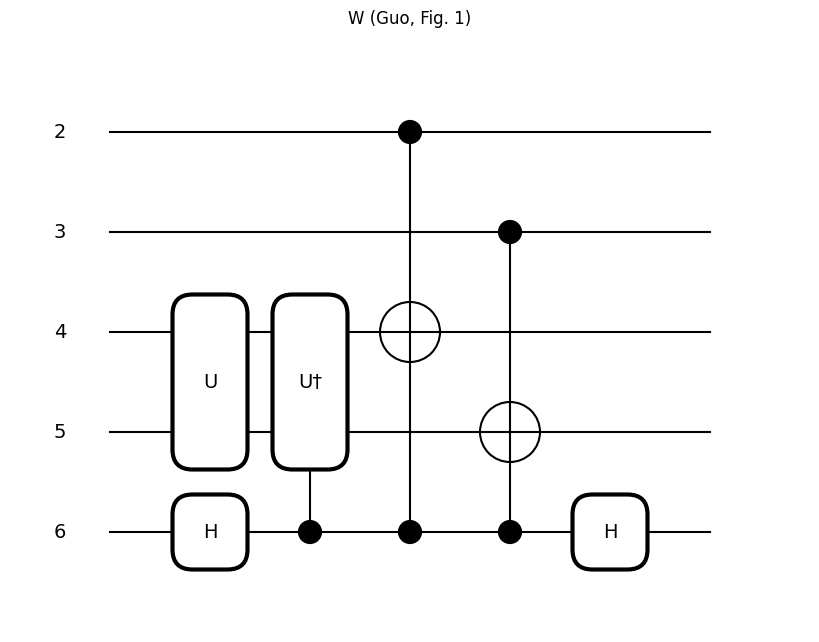

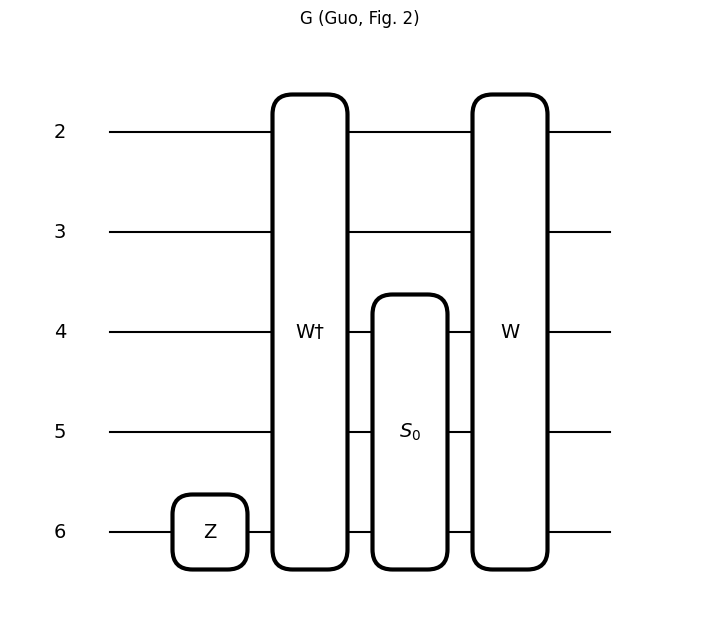

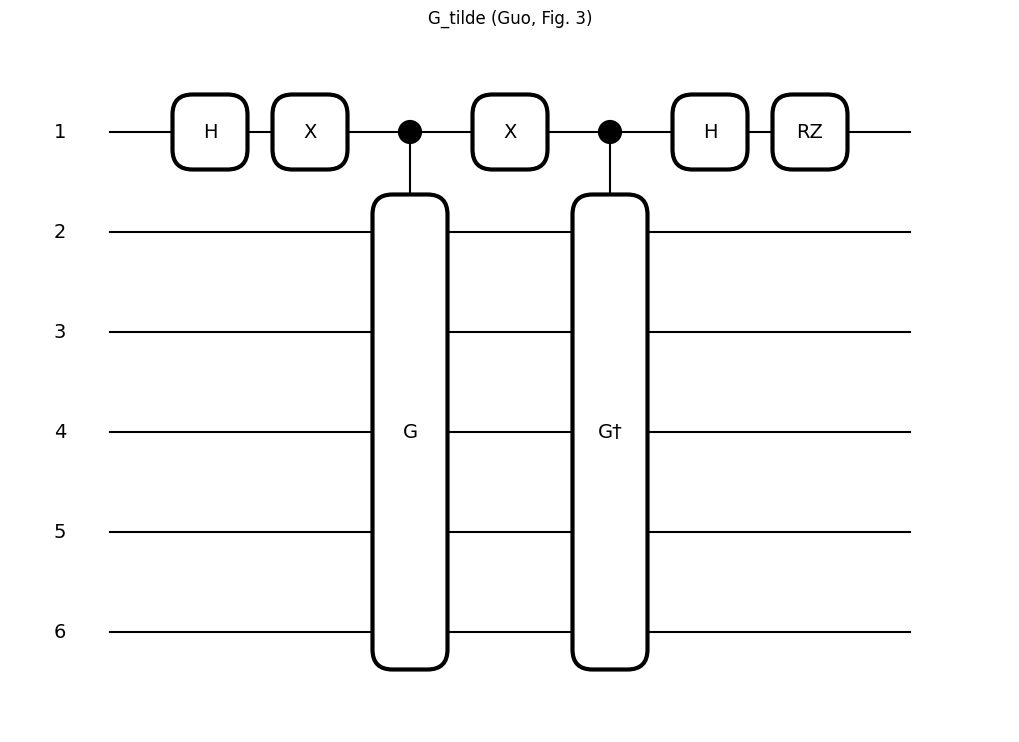

In [12]:
# W  [Guo: Fig. 1 | Tesi: Sez. 4.2.1 | Martyn: — | Gilyén: —]
fig, ax = qml.draw_mpl(W, wire_order=qubits_address + qubits_dati + ancilla_b)()
ax.set_title("W (Guo, Fig. 1)")
plt.show()

# G = W S_0 W^dagger Z_B  [Guo: Fig. 2 | Tesi: Sez. 4.2.2 | Martyn: — | Gilyén: —]
fig, ax = qml.draw_mpl(G, wire_order=qubits_address + qubits_dati + ancilla_b)()
ax.set_title("G (Guo, Fig. 2)")
plt.show()

# G_tilde  [Guo: Fig. 3 | Tesi: Sez. 4.2.3 | Martyn: — | Gilyén: —]
fig, ax = qml.draw_mpl(G_tilde, wire_order=qubits_gtilde_ad_da_b)()
ax.set_title("G_tilde (Guo, Fig. 3)")
plt.show()

## 3. QSVT: polinomio, angoli, gate $\mathcal{P}$

*Fonti:* [Guo: Lemma 3 | Tesi: Lemma 3.1, Sez. 3.4.3 | Martyn: Teorema 3 (Sez. II.C) | Gilyén: Teorema 56]

La QSVT applica un polinomio agli autovalori di una matrice codificata in un blocco di un'unitaria. Applicata a $\tilde G$, trasforma ogni $x_k$ in $P(x_k)$. La sezione ha tre passi: il polinomio (3.1), gli angoli di fase (3.2), il gate $\mathcal{P}$ (3.3).

### 3.1 Polinomio

**Scelta del polinomio.**
- *Metodo A:* il polinomio è dato direttamente con i suoi coefficienti (`ESEMPI_POLINOMI`).
- *Metodo B:* si approssima una funzione $f(x)$ (per esempio $\tanh$) con un polinomio di grado $d$, usando un fit di Chebyshev su $[-1, 1]$. Guo usa invece lo sviluppo di Taylor [Guo: App. C | Tesi: Eq. (3.25) | Martyn: — | Gilyén: —].

**Vincoli della QSVT** [Guo: — | Tesi: Sez. 3.4.4 | Martyn: Teorema 1, App. A.1 (Teoremi 9–10) | Gilyén: Corollario 10]:
- il polinomio deve avere **parità definita** (solo potenze pari o solo potenze dispari);
- deve valere $|P(x)| \le 1$ su $[-1, 1]$.

*Parità.* Nel metodo A la parità si ricava dai coefficienti, nel metodo B è dichiarata nei parametri. I coefficienti di parità sbagliata più piccoli di `TOLLERANZA_PARITA` sono errori numerici del fit e vengono messi a zero. Se sono più grandi il polinomio ha parità mista e il notebook si ferma con un errore: la combinazione di parte pari e parte dispari [Guo: Lemma 3 | Tesi: Lemma 3.1 | Martyn: — | Gilyén: Teorema 56] non è implementata.

*Scala.* Per rispettare il secondo vincolo, se $\max_{[-1,1]} |P'| > 0.999$ il polinomio viene diviso per il fattore di scala $s$ (`scala_qsvt`), che viene rimoltiplicato alla fine. Il massimo è calcolato su tutto $[-1, 1]$ (1000 punti), non solo negli $x_k$, perché la QSVT richiede il vincolo su tutto l'intervallo.

$s$ ha lo stesso ruolo del fattore $\gamma$ [Guo: Teorema 5 | Tesi: Eq. (4.19) | Martyn: — | Gilyén: —], $\gamma = \max_{[-1,1]} |P|$, ma non è lo stesso numero:
- **funzione o polinomio:** $\gamma$ è il massimo della funzione $P$, qui si calcola il massimo del polinomio $P'$ che la approssima (il codice conosce solo i suoi coefficienti). La differenza è al più $\varepsilon/(4N)$: con $\tanh$ di grado 5, $\gamma = \tanh(1) = 0.7616$ e $\max|P'| = 0.7624$;
- **si divide solo se serve:** $s = \max|P'| / 0.999$ se il massimo supera 0.999, altrimenti $s = 1$. Con $\tanh$ di grado 5 il polinomio non viene riscalato, mentre Guo dividerebbe comunque per $4\gamma \approx 3.05$;
- **niente fattore 4:** in Guo il polinomio passato al Lemma 3 è $P'/(4\gamma)$, con modulo al più $1/4$, come richiede quel lemma [Guo: Lemma 3, Eq. (5); Teorema 5 | Tesi: Eq. (3.17), Eq. (4.23) | Martyn: — | Gilyén: Teorema 56]. Qui gli angoli si calcolano con `qml.poly_to_angles` per la QSVT di PennyLane, che richiede solo $|P| \le 1$ [Guo: — | Tesi: Sez. 3.4.4 | Martyn: Teorema 1, App. A.1 (Teoremi 9–10) | Gilyén: Corollario 10]. Il margine 0.999 invece di 1 evita che $|P|$ tocchi esattamente 1.

In sintesi $s = \max\big(1,\ \max|P'|/0.999\big)$.

In [13]:
# ==========================================
# 3.1 Polinomio
# ==========================================

def stampa_polinomio(coeff_ascendenti):
    """Da [x^0, x^1, x^2, ...] alla stringa del polinomio (es. 0.1x^3 + 0.2x)."""
    termini = []
    grado_max = len(coeff_ascendenti) - 1

    # dal grado più alto al più basso
    for i, c in enumerate(reversed(coeff_ascendenti)):
        esponente = grado_max - i
        if c == 0:
            continue
        if esponente == 0:
            termini.append(f"{c}")
        elif esponente == 1:
            termini.append(f"{c}x")
        else:
            termini.append(f"{c}x^{esponente}")

    # unisce i termini e sistema i segni negativi (evita "+ -")
    return "0" if not termini else " + ".join(termini).replace("+ -", "- ")

def parita_definita(coefficienti, tolleranza=TOLLERANZA_PARITA):
    """Restituisce 'pari' o 'dispari'. Si ferma con un errore se il polinomio ha parità mista."""
    c = np.asarray(coefficienti, dtype=float)
    max_pari = np.max(np.abs(c[0::2]), initial=0.0)
    max_dispari = np.max(np.abs(c[1::2]), initial=0.0)
    if max_dispari <= tolleranza:
        return 'pari'
    if max_pari <= tolleranza:
        return 'dispari'
    raise ValueError(
        f"Polinomio di parità mista (coefficiente pari massimo {max_pari:.2e}, dispari massimo {max_dispari:.2e}). "
        "La QSVT richiede parità definita [Guo: — | Tesi: Sez. 3.4.4 | Martyn: Teorema 1 | Gilyén: Corollario 10]; "
        "la combinazione di parte pari e parte dispari [Guo: Lemma 3 | Tesi: Lemma 3.1 | Martyn: — | Gilyén: Teorema 56] non è implementata."
    )

def azzera_parita_sbagliata(coefficienti, parita, tolleranza=TOLLERANZA_PARITA):
    """Mette a zero i coefficienti di parità sbagliata se sono errori numerici (sotto la tolleranza).
    Se sono più grandi si ferma con un errore invece di toglierli senza avvisare."""
    c = np.array(coefficienti, dtype=float)
    sbagliati = c[1::2] if parita == 'pari' else c[0::2]
    massimo = np.max(np.abs(sbagliati), initial=0.0)
    if massimo > tolleranza:
        raise ValueError(
            f"Il polinomio non è {parita}: un coefficiente di parità sbagliata vale {massimo:.2e} "
            f"(tolleranza {tolleranza:.0e}). Controllare la parità dichiarata o il polinomio."
        )
    if parita == 'pari':
        c[1::2] = 0.0
    else:
        c[0::2] = 0.0
    return c

def coefficienti_da_funzione(funzione, grado):
    """Metodo B: fit di Chebyshev di f su [-1, 1], convertito in coefficienti [x^0, x^1, ...]."""
    x_punti = np.linspace(-1, 1, 1000)
    cheb_approssimazione = Chebyshev.fit(x_punti, funzione(x_punti), deg=grado)
    return cheb_approssimazione.convert(kind=Polynomial).coef

def riscala_polinomio(coefficienti, limite=0.999):
    """Divide il polinomio per s se max|P| su [-1, 1] supera il limite. Restituisce (coefficienti, s)."""
    # Taglio degli zeri in coda: senza, poly_to_angles va in errore (problema trovato con il grado 6)
    c = np.trim_zeros(coefficienti, 'b') # b=back, la coda della lista
    if len(c) == 0:
        c = np.array([0.0])

    x_test = np.linspace(-1, 1, 1000)
    # max |P'(x)| su [-1, 1] (1000 punti): analogo di γ [Guo: Teorema 5 | Tesi: Eq. (4.19) | Martyn: — | Gilyén: —], ma calcolato
    # sul polinomio P' e non sulla funzione P
    max_valore = np.max(np.abs(np.polyval(c[::-1], x_test))) 

    # a differenza di P'/(4γ) [Guo: Teorema 5 | Tesi: Eq. (4.23) | Martyn: — | Gilyén: —], si divide solo se serve, per s = max/0.999:
    # la QSVT di PennyLane richiede |P| <= 1, non 1/4
    fattore_di_scala = 1.0
    if max_valore > limite:
        fattore_di_scala = max_valore / limite
        c = c / fattore_di_scala
    return c, fattore_di_scala

print("\n--- POLINOMIO DA APPLICARE ---")
if usa_metodo_A:
    lista_coefficienti = ESEMPI_POLINOMI[SCELTA_POLINOMIO]
    parita = parita_definita(lista_coefficienti)
    coefficienti = azzera_parita_sbagliata(lista_coefficienti, parita)
    funzione_obiettivo = lambda t: sum(c * t**i for i, c in enumerate(lista_coefficienti))
    nome_obiettivo = f"P(x) = {stampa_polinomio(lista_coefficienti)}"
    print(f"Metodo A (polinomio dato): {nome_obiettivo}")
else:
    parita = parita_manuale
    coefficienti = azzera_parita_sbagliata(coefficienti_da_funzione(mia_funzione, grado_desiderato), parita)
    funzione_obiettivo = mia_funzione
    nome_obiettivo = f"f(x) = {NOME_FUNZIONE}"
    print(f"Metodo B (approssimazione di Chebyshev di grado {grado_desiderato}): {nome_obiettivo}")

coefficienti_qsvt, scala_qsvt = riscala_polinomio(coefficienti)

print("Parità:", parita)
print("Grado:", len(coefficienti_qsvt) - 1)
print("Scala QSVT:", scala_qsvt)


--- POLINOMIO DA APPLICARE ---
Metodo B (approssimazione di Chebyshev di grado 5): f(x) = tanh(x)
Parità: dispari
Grado: 5
Scala QSVT: 1.0


### 3.2 Angoli di fase

`qml.poly_to_angles` calcola gli angoli di fase $\Phi = (\varphi_0, \dots, \varphi_d)$ che realizzano il polinomio riscalato. Se il calcolo fallisce il notebook si ferma: con angoli inventati il circuito darebbe risultati sbagliati senza avvisare.

In [14]:
# ==========================================
# 3.2 Angoli di fase
# ==========================================

# Calcolo degli angoli con PyQSP (usato nelle prime versioni, poi sostituito da qml.poly_to_angles):
# angoli = np.array(QuantumSignalProcessingPhases(coefficienti, signal_operator="Wx"))

try:
    #qml.poly_to_angles(poly, routine/algoritmo di destinazione degli angoli, metodo per calcolare gli angoli)
    angoli_fase_qsvt = np.array(qml.poly_to_angles(coefficienti_qsvt, "QSVT", angle_solver='iterative'))
except Exception as e:
    raise RuntimeError(f"Errore nella generazione degli angoli QSVT: {e}") from e

print(f"Angoli di fase ({len(angoli_fase_qsvt)}):\n{angoli_fase_qsvt}")

Angoli di fase (6):
[-4.71533876e+00  1.60399192e+00  1.10700834e+00  1.10700834e+00
  1.60399192e+00 -2.94978394e-03]


### 3.3 Gate $\mathcal{P}$

*Fonti:* [Guo: — | Tesi: ___ | Martyn: Sez. II.A, Eq. (27), Fig. 3, Sez. II.E (ultimo paragrafo) | Gilyén: Corollario 18, Lemma 19, Fig. 1b, nota 14]

Ogni angolo diventa una rotazione di fase sul blocco, $e^{i\varphi(2\Pi - I)}$ [Guo: — | Tesi: ___ | Martyn: Eq. (27) | Gilyén: Teorema 17], dove il proiettore $\Pi = |0\rangle\langle 0|_{\tilde G} \otimes I$ individua il blocco in cui `ancilla_gtilde` è in $|0\rangle$. In PennyLane questa rotazione, sul solo filo del proiettore, è `qml.PCPhase(φ, dim=1)`: vale $e^{i\varphi}$ con `ancilla_gtilde` in $|0\rangle$ ed $e^{-i\varphi}$ con `ancilla_gtilde` in $|1\rangle$. Usata da sola, però, lascia nel blocco $P + iR$ invece di $P$ (paragrafo seguente); per avere $P$ la rotazione si costruisce con un'ancilla, come descritto sotto. `qml.QSVT` alterna $\tilde G$, $\tilde G^\dagger$ e le rotazioni di fase [Guo: — | Tesi: Sez. 3.4.3 | Martyn: Teorema 4 (Sez. II.D) | Gilyén: Teorema 17].

**Perché serve estrarre la parte reale.** Con gli angoli $\Phi$ di `qml.poly_to_angles` il blocco vale $P(x) + i\,R(x)$, non $P(x)$ [Guo: — | Tesi: ___ | Martyn: Teorema 1 | Gilyén: Corollario 10]. $R$ è imposta dall'unitarietà: in $x = \pm 1$ il blocco deve avere modulo 1, mentre $|P(\pm 1)| < 1$ (es.: con $\tanh$ di grado 5, $P(1) = 0.7624$ e il blocco vale $0.7624 + 0.6471\,i$). Con gli angoli $-\Phi$ il blocco è il coniugato $P(x) - i\,R(x)$ e la media delle due sequenze è $P(x)$ [Guo: — | Tesi: ___ | Martyn: — | Gilyén: Corollario 18].

**Come si fa nel circuito.** Ogni rotazione di fase usa l'ancilla `ancilla_reale` (l'ancilla $b$ di Gilyén): $C_\Pi\mathrm{NOT}$, $R_z(2\varphi)$ su `ancilla_reale`, $C_\Pi\mathrm{NOT}$ [Guo: — | Tesi: ___ | Martyn: Fig. 3 | Gilyén: Lemma 19, Fig. 1b]. $C_\Pi\mathrm{NOT}$ inverte `ancilla_reale` quando `ancilla_gtilde` è in $|0\rangle$, cioè nel blocco $\Pi$: è un CNOT controllato su 0, scritto $X$, CNOT, $X$ come per $G$ nella sezione 2.4.

| `ancilla_reale` | la porta vale | in PennyLane |
|---|---|---|
| $\vert 0\rangle$ | $e^{i\varphi(2\Pi - I)}$ | `PCPhase(φ, dim=1)` |
| $\vert 1\rangle$ | $e^{-i\varphi(2\Pi - I)}$ | `PCPhase(−φ, dim=1)` |

In entrambi i casi `ancilla_reale` torna com'era. Le Hadamard su `ancilla_reale` prima e dopo la QSVT la mettono in $|+\rangle$ e ricombinano i due rami: nella componente con `ancilla_reale` in $|0\rangle$ resta $\tfrac12(P + iR) + \tfrac12(P - iR) = P$ [Guo: — | Tesi: ___ | Martyn: Sez. II.E (ultimo paragrafo) | Gilyén: Corollario 18, nota 14].

**Per la tesi: costo della parte reale nel circuito.** +1 qubit (`ancilla_reale`) e $2(d+1)$ $C_\Pi\mathrm{NOT}$, cioè $2(d+1)$ CNOT e $4(d+1)$ porte $X$, più 2 Hadamard; con $\tanh$ di grado 5 ($d = 5$, 6 angoli): 12 CNOT e 24 $X$. Sono il costo rispetto a usare direttamente `qml.PCPhase`, che non richiede ancilla ma lascia $R$ nel blocco, da togliere poi in post-elaborazione con `.real`.

**$\tilde G$ come blocco.** $\tilde G$ è passato a `qml.QSVT` come `Blocco(G_tilde, ...)` (sezione 2): un unico operatore fatto delle porte della sezione 2, senza calcolarne la matrice. Anche ogni rotazione di fase è un blocco, chiamato $\Pi_{\varphi_j}$ come in Martyn, Eq. (27). La matrice di $\tilde G$ serve solo per la verifica della sezione 2.

In [15]:
# ==========================================
# 3.3 Gate P_corsivo  [Guo: — | Tesi: ___ | Martyn: Eq. (27), Fig. 3 | Gilyén: Corollario 18, Lemma 19, Fig. 1b]
# ==========================================

# G_tilde come blocco: un operatore fatto delle sue porte (non come matrice calcolata classicamente)
operatore_G_tilde = Blocco(G_tilde, r"$\tilde{G}$", qubits_gtilde_ad_da_b)

def rotazione_fase(angolo):
    """Rotazione di fase con l'ancilla b di Gilyén (Fig. 1b): C_Pi NOT, Rz(2 phi) su ancilla_reale, C_Pi NOT.
    Vale e^{i phi (2Pi - I)} con ancilla_reale in |0> ed e^{-i phi (2Pi - I)} con ancilla_reale in |1>.
    Le porte sono scritte nell'ordine in cui vengono applicate."""
    # 1. C_Pi NOT: NOT su ancilla_reale quando ancilla_gtilde è in |0> (il blocco Pi).
    #    Controllo su 0 (pallino bianco): X, CNOT, X
    qml.PauliX(wires=ancilla_gtilde)
    qml.CNOT(wires=[ancilla_gtilde[0], ancilla_reale[0]])   # [controllo, bersaglio]
    qml.PauliX(wires=ancilla_gtilde)

    # 2. Rz(2 phi) su ancilla_reale
    qml.RZ(2 * angolo, wires=ancilla_reale)

    # 3. C_Pi NOT di nuovo: riporta ancilla_reale com'era
    qml.PauliX(wires=ancilla_gtilde)
    qml.CNOT(wires=[ancilla_gtilde[0], ancilla_reale[0]])
    qml.PauliX(wires=ancilla_gtilde)

# qml.QSVT vuole un operatore per ogni angolo: un blocco con le porte di rotazione_fase, come per G_tilde.
# Con ancilla_reale in |0> ognuno vale qml.PCPhase(angolo, dim=1), in |1> qml.PCPhase(-angolo, dim=1)
lista_proiettori = [Blocco(partial(rotazione_fase, angolo), rf"$\Pi_{{\varphi_{{{j}}}}}$", ancilla_reale + ancilla_gtilde)
                    for j, angolo in enumerate(angoli_fase_qsvt)]

def P_corsivo():
    """Gate P_corsivo: QSVT di G_tilde con le rotazioni di fase con ancilla, tra due Hadamard su ancilla_reale.
    Con ancilla_reale in |0> all'inizio e alla fine il blocco vale P (Gilyén, Corollario 18), non P + iR."""
    qml.Hadamard(wires=ancilla_reale)   # |+>: sovrapposizione delle sequenze con angoli Phi e -Phi
    qml.QSVT(operatore_G_tilde, lista_proiettori)
    qml.Hadamard(wires=ancilla_reale)   # con ancilla_reale in |0> resta (P + iR)/2 + (P - iR)/2 = P

numero_rotazioni = len(lista_proiettori)
print("Gate P_corsivo costruito:", numero_rotazioni, "rotazioni di fase (Fig. 1b),", numero_rotazioni - 1, "chiamate a G_tilde o G_tilde^dagger")
print(f"Costo della parte reale nel circuito: 1 qubit, {2 * numero_rotazioni} CNOT, {4 * numero_rotazioni} X, 2 Hadamard")

Gate P_corsivo costruito: 6 rotazioni di fase (Fig. 1b), 5 chiamate a G_tilde o G_tilde^dagger
Costo della parte reale nel circuito: 1 qubit, 12 CNOT, 24 X, 2 Hadamard


### 3.4 Disegno di $\mathcal{P}$: la QSVT aperta di un livello

*Fonti:* [Guo: Lemma 3 | Tesi: Sez. 3.4.3 | Martyn: Teorema 4 (Sez. II.D) | Gilyén: Teorema 17]

Dentro la scatola QSVT: $\tilde G$ e $\tilde G^\dagger$ alternati, con una rotazione di fase prima, tra uno e l'altro e dopo ($\Pi_{\varphi_0}, \dots, \Pi_{\varphi_d}$, ognuna con le porte della Fig. 1b), tra le due Hadamard su `ancilla_reale`. Con grado $d$ ci sono $d$ chiamate a $\tilde G$ o $\tilde G^\dagger$ e $d + 1$ rotazioni.

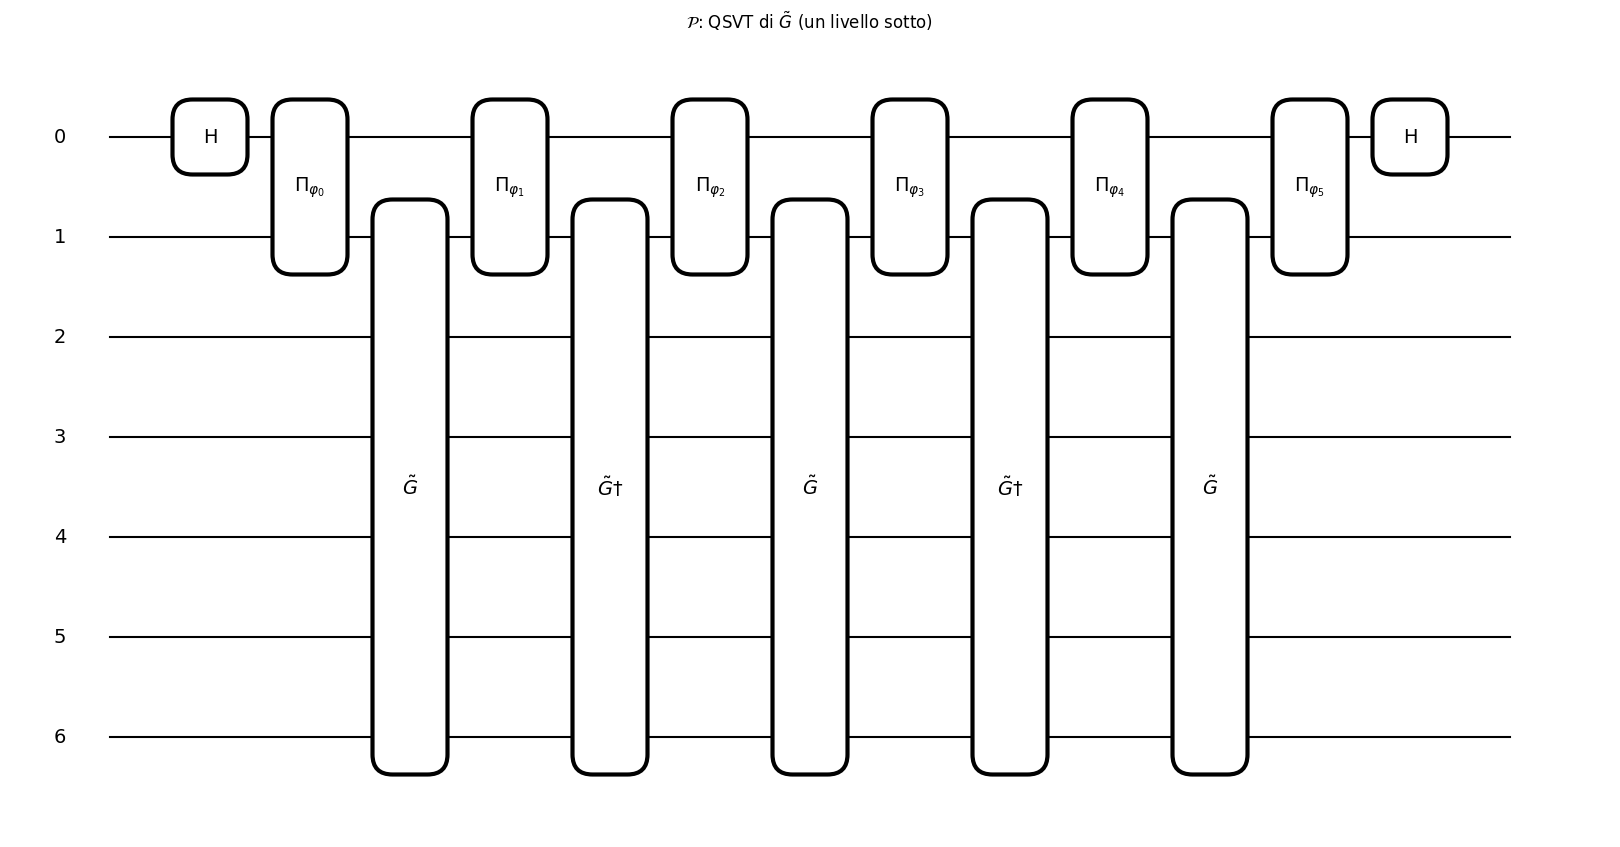

In [16]:
# 3.4 P_corsivo con la QSVT aperta di un livello: G_tilde, G_tilde^dagger e rotazioni di fase come blocchi
from pennylane.ops.op_math.change_op_basis import ChangeOpBasis

def applica_aperto(porta):
    """Applica una porta; se è un prodotto di porte (qml.prod o ChangeOpBasis, usati dalla QSVT) applica i fattori,
    per primo l'ultimo."""
    if isinstance(porta, (qml.ops.Prod, ChangeOpBasis)):
        for fattore in reversed(porta.operands):
            applica_aperto(fattore)
    else:
        qml.apply(porta)

def disegno_P_corsivo():
    with qml.QueuingManager.stop_recording():
        porte_qsvt = qml.QSVT(operatore_G_tilde, lista_proiettori).decomposition()   # in ordine di applicazione
    qml.Hadamard(wires=ancilla_reale)
    for porta in porte_qsvt:
        applica_aperto(porta)   # la QSVT raggruppa G_tilde^dagger, rotazione e G_tilde in un unico prodotto
    qml.Hadamard(wires=ancilla_reale)

fig, ax = qml.draw_mpl(disegno_P_corsivo, wire_order=ancilla_reale + qubits_gtilde_ad_da_b)()
ax.set_title(r"$\mathcal{P}$: QSVT di $\tilde{G}$ (un livello sotto)")
plt.show()

### 3.5 Verifica e disegno: rotazione di fase della Fig. 1b

*Fonti:* [Guo: — | Tesi: ___ | Martyn: Eq. (27), Fig. 3 | Gilyén: Lemma 19, Fig. 1b]

`rotazione_fase(φ)` agisce su `ancilla_gtilde` e `ancilla_reale`. Fissato lo stato di `ancilla_reale`, deve valere `PCPhase(φ)` se `ancilla_reale` è in $|0\rangle$ e `PCPhase(−φ)` se è in $|1\rangle$, senza cambiare `ancilla_reale`. Il controllo si fa per tutti gli angoli; il disegno mostra la porta per il primo angolo.

--- VERIFICA ROTAZIONE DI FASE (Fig. 1b) ---
phi_0 = -4.7153:  con |0> PCPhase(phi): sì   con |1> PCPhase(-phi): sì   ancilla_reale invariata: sì
phi_1 = +1.6040:  con |0> PCPhase(phi): sì   con |1> PCPhase(-phi): sì   ancilla_reale invariata: sì
phi_2 = +1.1070:  con |0> PCPhase(phi): sì   con |1> PCPhase(-phi): sì   ancilla_reale invariata: sì
phi_3 = +1.1070:  con |0> PCPhase(phi): sì   con |1> PCPhase(-phi): sì   ancilla_reale invariata: sì
phi_4 = +1.6040:  con |0> PCPhase(phi): sì   con |1> PCPhase(-phi): sì   ancilla_reale invariata: sì
phi_5 = -0.0029:  con |0> PCPhase(phi): sì   con |1> PCPhase(-phi): sì   ancilla_reale invariata: sì

Tutte le rotazioni sono corrette: True


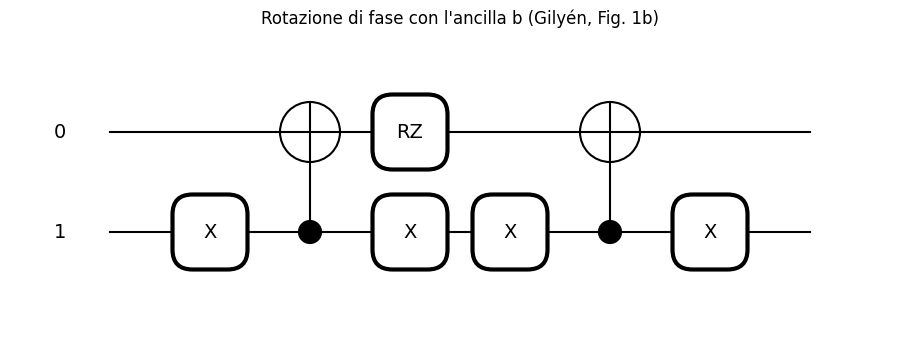

In [17]:
# 3.5 VERIFICA: rotazione = PCPhase(phi) con ancilla_reale in |0>, PCPhase(-phi) con ancilla_reale in |1>
fili_fase = ancilla_gtilde + ancilla_reale        # indice di riga = 2*(ancilla_gtilde) + (ancilla_reale)
reale_0, reale_1 = [0, 2], [1, 3]                 # righe e colonne con ancilla_reale in |0> e in |1>

print("--- VERIFICA ROTAZIONE DI FASE (Fig. 1b) ---")
tutte_corrette = True
for j, angolo in enumerate(angoli_fase_qsvt):
    M = qml.matrix(rotazione_fase, wire_order=fili_fase)(angolo)
    con_0 = np.allclose(M[np.ix_(reale_0, reale_0)], qml.matrix(qml.PCPhase(angolo, dim=1, wires=ancilla_gtilde)))
    con_1 = np.allclose(M[np.ix_(reale_1, reale_1)], qml.matrix(qml.PCPhase(-angolo, dim=1, wires=ancilla_gtilde)))
    invariata = np.allclose(M[np.ix_(reale_0, reale_1)], 0) and np.allclose(M[np.ix_(reale_1, reale_0)], 0)
    corretta = con_0 and con_1 and invariata
    tutte_corrette = tutte_corrette and corretta
    print(f"phi_{j} = {angolo:+.4f}:  con |0> PCPhase(phi): {'sì' if con_0 else 'NO'}   "
          f"con |1> PCPhase(-phi): {'sì' if con_1 else 'NO'}   ancilla_reale invariata: {'sì' if invariata else 'NO'}")
print("\nTutte le rotazioni sono corrette:", tutte_corrette)

# Disegno della rotazione per il primo angolo (ancilla_reale sopra ancilla_gtilde)
fig, ax = qml.draw_mpl(rotazione_fase, wire_order=ancilla_reale + ancilla_gtilde)(angoli_fase_qsvt[0])
ax.set_title("Rotazione di fase con l'ancilla b (Gilyén, Fig. 1b)")
plt.show()

## 4. Circuito finale ed estrazione dei risultati

*Fonti:* [Guo: Teorema 5, Fig. 4, Eq. (22) | Tesi: Sez. 4.3.3, Eq. (4.26)–(4.30) | Martyn: — | Gilyén: —]

Il circuito è la versione per il caso reale della Fig. 4 di Guo:

$$H^{\otimes n}_{ad} \;\rightarrow\; W \;\rightarrow\; \mathcal{P} \;\rightarrow\; W^\dagger$$

Le Hadamard creano la sovrapposizione uniforme degli indirizzi, $W$ porta ogni $|k\rangle$ in un autovettore di $\tilde G$ con autovalore $x_k$, $\mathcal{P}$ applica il polinomio, $W^\dagger$ riporta a zero i registri dati e B. Guo ottiene lo stato

$$\frac{1}{2\gamma\sqrt{N}} \sum_{k} P'(x_k)\, |0\rangle^{\otimes 3}\, |k\rangle_{ad}\, |0\rangle^{\otimes n+1}_{da,B} + \cdots$$

dove $|0\rangle^{\otimes 3}$ sono le tre ancille di Guo; qui ci sono `ancilla_reale` e `ancilla_gtilde` (sezione 1).

Il circuito è definito una volta sola (`circuito_stato_finale`) e riusato nel disegno e nella sezione 5; `calcola_stato_finale` lo esegue e restituisce il vettore di stato.

**Estrazione.** `estrai_risultati` prende le ampiezze in cui `ancilla_reale`, `ancilla_gtilde`, i dati e B sono a 0, al variare degli indirizzi; i fili sono indicati per nome, non per posizione dei bit. Per ogni indirizzo $k$ si moltiplica per $\sqrt{N}$ (per compensare le Hadamard) e per il fattore di scala.

**Nota: parte reale.** Con `qml.PCPhase` al posto della rotazione della sezione 3.3, l'ampiezza estratta sarebbe $P(x) + i\,R(x)$ e la parte reale andrebbe presa in post-elaborazione con `.real`. $R$ è un polinomio "di servizio" della QSVT (sezione 3.3), non la funzione $Q$ del paper [Guo: Def. 1, Teorema 5 | Tesi: Sez. 4.1, Eq. (4.2) | Martyn: — | Gilyén: —], che agisce sulle parti immaginarie $y_k$ dei dati e qui non è implementata. Qui la parte reale si ottiene nel circuito con `ancilla_reale` (sezione 3.3): l'ampiezza estratta vale già $P(x)$, con parte immaginaria nulla fino agli errori numerici. La cella stampa il massimo della parte immaginaria e si ferma se supera $10^{-8}$; `np.real` serve poi solo a cambiare il tipo dei numeri da complesso a reale.

### 4.1 Esecuzione ed estrazione delle ampiezze

In [18]:
# ==========================================
# 4.1 Circuito finale ed estrazione  [Guo: Teorema 5, Eq. (22) | Tesi: Sez. 4.3.3, Eq. (4.30) | Martyn: — | Gilyén: —]
# ==========================================

def estrai_risultati(stato, fili, fili_indirizzo, fili_a_zero):
    """Ampiezze del vettore di stato con i fili_a_zero in |0>, una per ogni valore degli indirizzi.
    fili: ordine dei fili del dispositivo. Ogni filo deve essere di indirizzo o a zero."""
    psi = np.asarray(stato).reshape([2] * len(fili))
    indice = []
    for f in fili:
        if f in fili_a_zero:
            indice.append(0)
        elif f in fili_indirizzo:
            indice.append(slice(None))
        else:
            raise ValueError(f"Il filo {f} non è né di indirizzo né a zero")
    return psi[tuple(indice)].reshape(-1)

def circuito_stato_finale():
    """H sugli address -> W -> P_corsivo -> W^dagger"""
    # a) Hadamard sugli address: sovrapposizione uniforme degli indirizzi
    for wire in qubits_address:
        qml.Hadamard(wires=wire)

    # b) W: lega i dati agli indirizzi
    Blocco(W, "W", qubits_ad_da_b)

    # c) P_corsivo: applica il polinomio con la QSVT (parte reale con ancilla_reale)
    Blocco(P_corsivo, r"$\mathcal{P}$", ancilla_reale + qubits_gtilde_ad_da_b)

    # d) W^dagger: riporta a zero dati e B
    qml.adjoint(Blocco(W, "W", qubits_ad_da_b))

dev_finale = qml.device("default.qubit", wires=tutti_i_fili)

@partial(qml.transforms.decompose, gate_set=PORTE_ELEMENTARI)   # esegue le porte elementari (cella dei blocchi)
@qml.qnode(dev_finale)
def calcola_stato_finale():
    circuito_stato_finale()
    return qml.state()

print("--- ESECUZIONE DEL CIRCUITO FINALE ---")
stato_ntca = calcola_stato_finale()
print(f"Vettore di stato: {len(stato_ntca)} ampiezze (2^{len(tutti_i_fili)})\n")

# Ampiezze con ancilla_reale, ancilla_gtilde, dati e B a 0; per sqrt(N_pad) per compensare le Hadamard iniziali
fili_a_zero = ancilla_reale + ancilla_gtilde + qubits_dati + ancilla_b
risultati_quantistici = estrai_risultati(stato_ntca, tutti_i_fili, qubits_address, fili_a_zero) * np.sqrt(N_pad)

print("--- AMPIEZZE ESTRATTE (P) ---")
for k, valore in enumerate(risultati_quantistici):
    print(f"Indirizzo |{k}> : {np.round(valore, 4)}")
print()

# Parte immaginaria: con ancilla_reale si cancella nel circuito (senza, sarebbe R(x_k))
parte_immaginaria_max = np.max(np.abs(risultati_quantistici.imag))
print(f"Parte immaginaria massima delle ampiezze: {parte_immaginaria_max:.1e}\n")
if parte_immaginaria_max > 1e-8:
    raise ValueError(f"Parte immaginaria {parte_immaginaria_max:.1e}: il circuito non ha prodotto la sola parte reale")

# Valori per il fattore di scala. np.real cambia solo il tipo (da complesso a reale): la parte immaginaria è già nulla
valori_circuito = np.real(risultati_quantistici) * scala_qsvt

print("--- RISULTATI (ampiezze per la scala) ---")
for k, valore in enumerate(valori_circuito):
    print(f"Indirizzo |{k}> : {valore:.4f}")

--- ESECUZIONE DEL CIRCUITO FINALE ---
Vettore di stato: 128 ampiezze (2^7)

--- AMPIEZZE ESTRATTE (P) ---
Indirizzo |0> : (0.6913+0j)
Indirizzo |1> : (-0.4225-0j)
Indirizzo |2> : (-0.2449-0j)
Indirizzo |3> : (0.0996-0j)

Parte immaginaria massima delle ampiezze: 2.9e-14

--- RISULTATI (ampiezze per la scala) ---
Indirizzo |0> : 0.6913
Indirizzo |1> : -0.4225
Indirizzo |2> : -0.2449
Indirizzo |3> : 0.0996


### 4.2 Disegno del circuito finale

Il blocco $\mathcal{P}$ agisce su `ancilla_reale` (rotazioni di fase della Fig. 1b), su `ancilla_gtilde` (filo del proiettore) e sui registri address, data e B. 

Il disegno è a blocchi: $W$, $\mathcal{P}$ e $W^\dagger$ sono scatole. $\mathcal{P}$ contiene le due Hadamard su `ancilla_reale` e la QSVT; il suo contenuto è disegnato nella sezione 3.3.

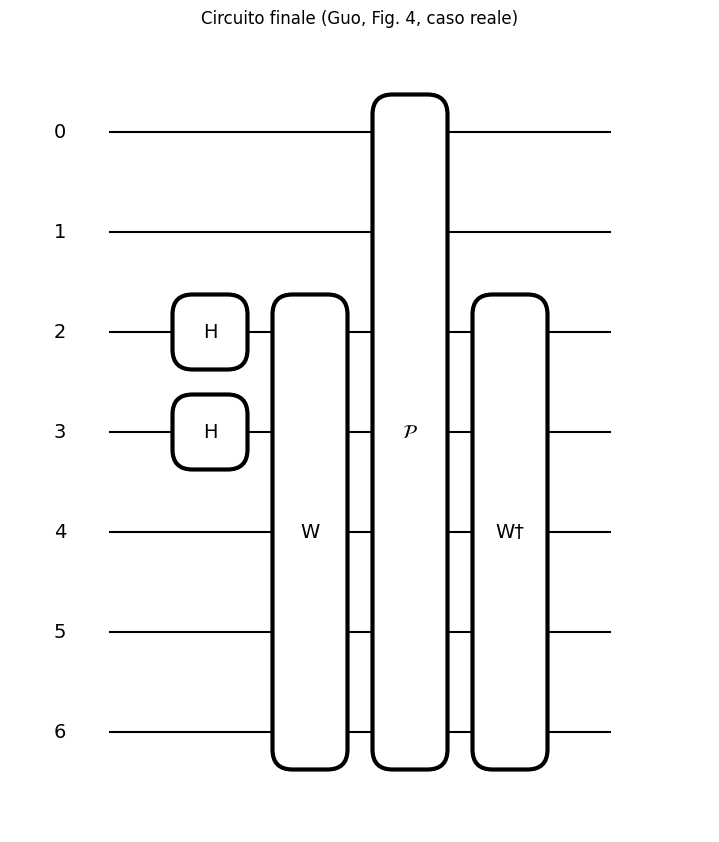

In [19]:
# 4.2 Circuito finale: H sugli address -> W -> P_corsivo (QSVT) -> W^dagger
fig, ax = qml.draw_mpl(circuito_stato_finale, wire_order=tutti_i_fili, show_all_wires=True)()
ax.set_title("Circuito finale (Guo, Fig. 4, caso reale)")
plt.show()

### 4.3 Lettura dei risultati: postselezione e hardware

*Fonti:* [Guo: Def. 1, Eq. (22), Sez. IV | Tesi: Sez. 3.2.4, Sez. 4.3.4, Eq. (4.31)–(4.32) | Martyn: — | Gilyén: —]

**Cosa fa il notebook.** Il circuito prepara lo stato; il notebook lo legge dal vettore di stato del simulatore (`qml.state()`), che mostra tutte le ampiezze senza disturbarle. È il modo per verificare che lo stato preparato sia quello voluto (Guo chiede di *preparare* lo stato, Def. 1), ma esiste solo in simulazione: un computer quantistico restituisce soltanto esiti di misura.

**Cosa servirebbe su un computer quantistico.**
1. *Postselezione.* Si misurano le ancille, i dati e B e si tengono solo le esecuzioni in cui escono tutti 0. In quelle il registro degli indirizzi è nello stato $\frac{1}{\sqrt{\kappa}}\sum_k P(x_k)\,|k\rangle$, con $\kappa = \sum_k P(x_k)^2$.
2. *Misura degli indirizzi.* Ogni misura dà un solo indirizzo $k$ (con $n = 2$: 00, 01, 10 o 11), con probabilità $P(x_k)^2/\kappa$. La probabilità è il quadrato dell'ampiezza: dalle frequenze si perdono il segno e la scala, e dopo la misura lo stato è collassato su $|k\rangle$.
3. *Stima.* Per ricavare un valore con il suo segno serve la stima di ampiezza. Guo (Sez. IV) stima $(1 + F)/2$, la cui ampiezza è sempre positiva se $|F| \le 1$: è la costruzione del termine noto della sezione 5.

In generale lo stato in uscita non si legge per intero, perché il numero di esecuzioni necessarie crescerebbe con $N$: è pensato come ingresso di altri passi quantistici, per esempio lo strato successivo di una rete neurale (Guo, Sez. IV).

**Probabilità di postselezione.** È la probabilità che ancille, dati e B risultino tutti a 0: $p = \sum_k |b_k|^2$, con $b_k$ le ampiezze estratte prima di moltiplicarle per $\sqrt{N}$. Con il polinomio diviso per $s$ vale $p = \sum_k P'(x_k)^2 / (s^2 N)$; in media servono $1/p$ esecuzioni per un successo. Guo divide il polinomio per $4\gamma$, quindi nel paper $p = \sum_k P'(x_k)^2 / (16\gamma^2 N)$, più piccola. La cella confronta il valore simulato con la formula, calcolata dai coefficienti del polinomio e non dal circuito. Con `qml.PCPhase` senza ancilla lo stato conterrebbe anche $i\,R(x_k)$ e $p$ includerebbe $|R|^2$, senza corrispondere alla formula.

**Più scale.** Il vincolo che la QSVT pone sul polinomio dipende dal caso [Guo: Lemma 3, Eq. (5) | Tesi: Sez. 4.3 | Martyn: Teorema 1 | Gilyén: Corollario 10, Teorema 56]:

| Caso | Vincolo | Scala |
|---|---|---|
| polinomio reale di parità definita (questo notebook, sezioni 3 e 4) | $\lvert P\rvert \le 1$ | $P'/s$: si divide solo se serve |
| polinomio reale di parità qualsiasi (il termine noto, sezione 5) | $\lvert P\rvert \le \tfrac12$ | fattore $\tfrac12$ della LCU |
| polinomio complesso di parità qualsiasi (Lemma 3 di Guo) | $\lvert P\rvert \le \tfrac14$ | $P'/(4\gamma)$ |

Ogni generalizzazione costa un fattore $\tfrac12$: uno per combinare parte pari e parte dispari, uno per combinare parte reale e parte immaginaria. Per questo $p$ è più grande di $p_{\mathrm{Guo}}$ di un fattore $16\gamma^2/s^2$ (circa 9.3 con $\tanh$ e $s = 1$).

**Il circuito su un computer quantistico.** Tutte le porte (preparazione di Möttönen, Toffoli, porte controllate, la QSVT scomposta in $\tilde G$, $\tilde G^\dagger$ e rotazioni di fase) sono porte standard: in linea di principio il circuito si può eseguire su hardware. Scomposto in porte elementari, però, è molto profondo: le versioni controllate di $G$ e $G^\dagger$, ripetute in ogni chiamata a $\tilde G$ della QSVT, e la preparazione dello stato generano migliaia di porte (la cella stampa il conteggio). Sull'hardware rumoroso di oggi il risultato sarebbe dominato dagli errori.

In [20]:
# ==========================================
# 4.3 Lettura dei risultati: probabilità di postselezione e risorse  [Guo: Def. 1, Eq. (22), Sez. IV | Tesi: Sez. 3.2.4, Sez. 4.3.4, Eq. (4.31)–(4.32) | Martyn: — | Gilyén: —]
# ==========================================

# 1. Probabilità di postselezione: ancille, dati e B tutti a 0 (ampiezze senza il fattore sqrt(N))
ampiezze_postselezione = estrai_risultati(stato_ntca, tutti_i_fili, qubits_address, fili_a_zero)
p_simulata = np.sum(np.abs(ampiezze_postselezione)**2)

# Formula dai coefficienti del polinomio riscalato (P'/s), non dal circuito
P_riscalato_k = np.polyval(coefficienti_qsvt[::-1], x)
p_formula = np.sum(P_riscalato_k**2) / N_pad

# Con la scala del paper, P'/(4 gamma), gamma = max |P| su [-1, 1]
gamma = np.max(np.abs(funzione_obiettivo(np.linspace(-1, 1, 1000))))
P_k = np.polyval(np.asarray(coefficienti)[::-1], x)
p_guo = np.sum(P_k**2) / (16 * gamma**2 * N_pad)

print("--- PROBABILITÀ DI POSTSELEZIONE ---")
print(f"p simulata (somma dei |b_k|^2):               {p_simulata:.4f}")
print(f"p dalla formula sum P'(x_k)^2 / (s^2 N):      {p_formula:.4f}")
print("coincidono:", np.isclose(p_simulata, p_formula))
print(f"1/p, esecuzioni in media per un successo:     {1 / p_simulata:.1f}")
print(f"p_Guo, con la scala del paper P'/(4γ):        {p_guo:.4f}  (γ = {gamma:.4f}, {1 / p_guo:.0f} esecuzioni per un successo)")

# 2. Risorse: il circuito finale scomposto in porte elementari
porte_base = {"CNOT", "RX", "RY", "RZ", "PhaseShift", "Hadamard", "PauliX", "GlobalPhase"}
risorse = qml.specs(qml.transforms.decompose(calcola_stato_finale, gate_set=porte_base))().resources
tipi = {nome: numero for nome, numero in risorse.gate_types.items() if nome != "GlobalPhase"}   # fase globale: non è una porta fisica

print("\n--- RISORSE DEL CIRCUITO FINALE (porte elementari, dalla più usata alla meno usata) ---")
print(f"qubit: {len(tutti_i_fili)}   porte: {sum(tipi.values())}   profondità: {risorse.depth}")
for nome, numero in sorted(tipi.items(), key=lambda kv: -kv[1]):
    print(f"  {nome}: {numero}")

--- PROBABILITÀ DI POSTSELEZIONE ---
p simulata (somma dei |b_k|^2):               0.1816
p dalla formula sum P'(x_k)^2 / (s^2 N):      0.1816
coincidono: True
1/p, esecuzioni in media per un successo:     5.5
p_Guo, con la scala del paper P'/(4γ):        0.0196  (γ = 0.7616, 51 esecuzioni per un successo)

--- RISORSE DEL CIRCUITO FINALE (porte elementari, dalla più usata alla meno usata) ---
qubit: 7   porte: 12905   profondità: 9792
  CNOT: 4308
  PhaseShift: 3352
  RZ: 2631
  RY: 1818
  Hadamard: 722
  PauliX: 74


### 4.4 Simulazione con misure (shots)

*Fonti:* [Guo: Eq. (22), Sez. IV | Tesi: Sez. 3.2.4, Sez. 4.3.4 | Martyn: — | Gilyén: —]

Il circuito finale viene eseguito come su un computer quantistico: invece del vettore di stato, `qml.sample` restituisce per ogni esecuzione (*shot*) la stringa di bit misurata su tutti i fili. Su `NUMERO_SHOTS` esecuzioni:
1. si tengono solo quelle con ancille, dati e B a 0 (postselezione): la frazione tenuta stima $p$;
2. tra quelle tenute si contano gli indirizzi: la frequenza di $k$ stima $P(x_k)^2/\kappa$;
3. il conteggio di $k$ diviso per tutti gli shot stima $|b_k|^2$, quindi $|P(x_k)| \approx s\sqrt{N \cdot \text{conteggio}_k / \text{shot}}$: la scala si recupera, il segno no.

**Errore statistico.** Il conteggio $n_k$ segue una distribuzione binomiale con $M$ prove (gli shot) e probabilità $q_k = |b_k|^2$. Propagando l'errore nella stima $|P| = s\sqrt{N n_k/M}$ si ottiene $\sigma_k = \tfrac{s}{2}\sqrt{N(1 - q_k)/M} \approx \tfrac{s}{2}\sqrt{N/M}$: lo stesso per tutti gli indirizzi, e per avere la stessa precisione gli shot devono crescere come $N$. La tabella riporta lo scarto tra stima e valore del circuito e $\sigma_k$; sotto, lo scarto massimo anche in unità di $\sigma$. Per gli indirizzi con $q_k$ quasi nullo l'approssimazione è grossolana, ma lì lo scarto è comunque piccolo.

Il seed del simulatore è fisso, quindi i numeri sono gli stessi a ogni esecuzione. Come si recupera anche il segno è mostrato nella sezione 5.

In [21]:
# ==========================================
# 4.4 Simulazione con misure (shots)  [Guo: Eq. (22), Sez. IV | Tesi: Sez. 3.2.4, Sez. 4.3.4 | Martyn: — | Gilyén: —]
# ==========================================

NUMERO_SHOTS = 10_000
dev_misure = qml.device("default.qubit", wires=tutti_i_fili, seed=1234)   # seed fisso: stessi numeri a ogni esecuzione

@qml.set_shots(NUMERO_SHOTS)
@partial(qml.transforms.decompose, gate_set=PORTE_ELEMENTARI)   # esegue le porte elementari (cella dei blocchi)
@qml.qnode(dev_misure)
def misura_stato_finale():
    circuito_stato_finale()
    return qml.sample(wires=tutti_i_fili)      # una riga per shot, un bit per filo

campioni = misura_stato_finale()
colonne_a_zero = [tutti_i_fili.index(filo) for filo in fili_a_zero]
colonne_indirizzo = [tutti_i_fili.index(filo) for filo in qubits_address]
pesi_bit = 2 ** np.arange(n - 1, -1, -1)       # primo filo degli indirizzi = bit più significativo

# 1. Postselezione: si tengono solo gli shot con ancille, dati e B a 0
tenuti = campioni[np.all(campioni[:, colonne_a_zero] == 0, axis=1)]
print("--- SIMULAZIONE CON MISURE ---")
print(f"shot (M): {NUMERO_SHOTS}   tenuti (M_ps): {len(tenuti)}   frazione (p^): {len(tenuti) / NUMERO_SHOTS:.4f}   (p esatta: {p_simulata:.4f})")

# 2. Indirizzi misurati negli shot tenuti
conteggi = np.bincount(tenuti[:, colonne_indirizzo] @ pesi_bit, minlength=N_pad)
kappa = np.sum(valori_circuito**2)

# 3. Stime: frequenza contro P^2/kappa, |P| dai conteggi
# Errore statistico atteso (binomiale, propagazione dell'errore): sigma_k = (s/2) sqrt(N (1 - q_k) / M), q_k = |b_k|^2
q_k = (valori_circuito / scala_qsvt)**2 / N_pad
sigma_k = scala_qsvt / 2 * np.sqrt(N_pad * (1 - q_k) / NUMERO_SHOTS)
P_stimati = scala_qsvt * np.sqrt(N_pad * conteggi / NUMERO_SHOTS)
scarti = np.abs(P_stimati - np.abs(valori_circuito))

# Intestazione su due righe: testo e simbolo della tesi
intest_testo   = ["k", "bit", "conteggio", "frequenza", "freq. attesa", "circuito", "|P| stimato", "scarto",        "sigma"]
intest_simboli = ["",  "",    "n_k",       "n_k/M_ps",  "c_k^2/κ",      "c_k",      "|P^(x_k)|",   "||P^| - |c_k||", "σ_k"]
larghezze      = [2,   4,     10,          10,          12,             9,          12,            15,               7]
print()
for riga in (intest_testo, intest_simboli):
    print(" ".join(f"{t:>{w}}" for t, w in zip(riga, larghezze)))
for k in range(N_pad):
    frequenza = conteggi[k] / max(len(tenuti), 1)
    print(f"{k:>2} {format(k, f'0{n}b'):>4} {conteggi[k]:>10} {frequenza:>10.4f} {valori_circuito[k]**2 / kappa:>12.4f}"
          f" {valori_circuito[k]:>+9.4f} {P_stimati[k]:>12.4f} {scarti[k]:>15.4f} {sigma_k[k]:>7.4f}")
print("\nIl segno non si ricava dai conteggi: P e -P danno la stessa frequenza.")
print(f"Scarto massimo, max_k ||P^| - |c_k||: {scarti.max():.4f}   sigma attesa, σ ~ (s/2) sqrt(N/M) = {scala_qsvt / 2 * np.sqrt(N_pad / NUMERO_SHOTS):.4f}"
      f"   scarto massimo in unità di sigma: {np.max(scarti / sigma_k):.1f}")

--- SIMULAZIONE CON MISURE ---
shot (M): 10000   tenuti (M_ps): 1818   frazione (p^): 0.1818   (p esatta: 0.1816)

 k  bit  conteggio  frequenza freq. attesa  circuito  |P| stimato          scarto   sigma
               n_k   n_k/M_ps      c_k^2/κ       c_k    |P^(x_k)|  ||P^| - |c_k||     σ_k
 0   00       1180     0.6491       0.6580   +0.6913       0.6870          0.0042  0.0094
 1   01        464     0.2552       0.2458   -0.4225       0.4308          0.0083  0.0098
 2   10        148     0.0814       0.0826   -0.2449       0.2433          0.0016  0.0099
 3   11         26     0.0143       0.0137   +0.0996       0.1020          0.0024  0.0100

Il segno non si ricava dai conteggi: P e -P danno la stessa frequenza.
Scarto massimo, max_k ||P^| - |c_k||: 0.0083   sigma attesa, σ ~ (s/2) sqrt(N/M) = 0.0100   scarto massimo in unità di sigma: 0.9


### 4.5 Verifica classica

Confronto con il calcolo classico: $P(x_k)$ per il metodo A, $f(x_k)$ per il metodo B. Nel metodo B le piccole differenze (circa $10^{-4}$) vengono dall'approssimazione di $f$ con un polinomio di grado $d$. La stessa funzione serve per la sezione 5, con termine noto 1.

In [22]:
# 4.5 Verifica classica: valori attesi f(x_k) + termine noto (metodo A: f è il polinomio dato)
def stampa_valori_attesi(dati_x, funzione, termine_noto=0.0):
    print("--- VERIFICA DI COERENZA CLASSICA ---")
    for k, x_k in enumerate(dati_x):
        print(f"Indirizzo |{k}> : {funzione(x_k) + termine_noto:.4f}")
    print()

stampa_valori_attesi(x, funzione_obiettivo)

--- VERIFICA DI COERENZA CLASSICA ---
Indirizzo |0> : 0.6916
Indirizzo |1> : -0.4224
Indirizzo |2> : -0.2452
Indirizzo |3> : 0.0998



### 4.6 Riepilogo dei risultati

Il grafico e la tabella mettono a confronto tre cose:
- **obiettivo:** $f(x)$ per il metodo B, il polinomio della lista per il metodo A;
- **$P'(x)$ realizzato dagli angoli:** il polinomio che la QSVT applica davvero. Si ottiene applicando la stessa sequenza di angoli a un block encoding di un solo qubit, come nell'esempio della documentazione di `qml.poly_to_angles`;
- **valori dal circuito:** i risultati della sezione 4 negli $x_k$.

Il circuito deve coincidere con $P'(x_k)$ fino agli errori numerici. La distanza dall'obiettivo misura invece l'errore dell'approssimazione polinomiale (metodo B); nel metodo A deve essere nulla.

L'errore rispetto all'obiettivo si stampa in due modi: negli $x_k$ (dipende anche da dove cadono i dati) e su tutto $[-1, 1]$, sulla griglia del grafico (dipende solo dalla funzione e dal grado). Il secondo è l'analogo, sul polinomio, dell'errore di approssimazione richiesto su tutto l'intervallo [Guo: Teorema 5 | Tesi: Sez. 3.4.4 | Martyn: — | Gilyén: —]; negli $x_k$ l'errore non può superarlo, a meno degli errori numerici.

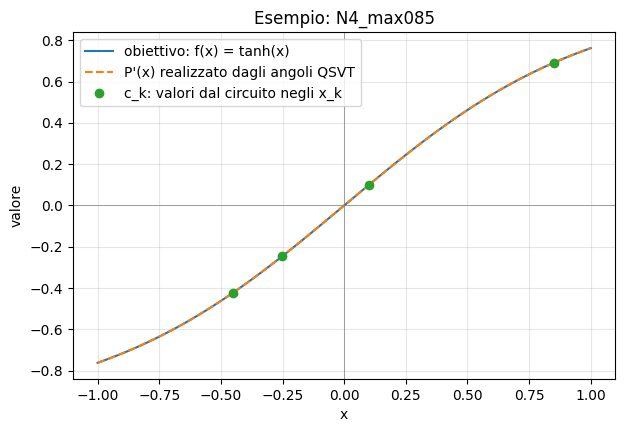

 k      dato  obiettivo  polinomio   circuito   errore dati   errore impl
         x_k     f(x_k)    P'(x_k)        c_k     |c_k - f|    |c_k - P'|
 0   +0.8511    +0.6916    +0.6913    +0.6913      3.65e-04      1.25e-14
 1   -0.4506    -0.4224    -0.4225    -0.4225      1.32e-04      1.09e-14
 2   -0.2503    -0.2452    -0.2449    -0.2449      2.85e-04      7.72e-15
 3   +0.1001    +0.0998    +0.0996    +0.0996      2.13e-04      4.94e-15

Errore di implementazione, ε_impl = max_k |c_k - P'(x_k)|: 1.25e-14
Il circuito realizza il polinomio P' (tolleranza 1e-8): True
Errore massimo rispetto all'obiettivo, ε_dati = max_k |c_k - f(x_k)|: 3.65e-04
Errore massimo su [-1, 1], ε_∞ = max_x |P'(x) - f(x)| (griglia di 201 punti): 8.51e-04


In [23]:
# 4.6 Riepilogo: funzione obiettivo, polinomio realizzato dagli angoli e valori del circuito
# (funzione_obiettivo e nome_obiettivo sono definiti nella sezione 1.1)

# 1. Polinomio realizzato dagli angoli: stessa QSVT su un block encoding di 1 qubit
#    (la parte reale del blocco, moltiplicata per la scala, è P'(t)).
#    Qui .real resta: è il calcolo classico di riferimento di cosa fanno gli angoli, non il circuito.
def polinomio_dagli_angoli(t):
    block_encoding = qml.RX(2 * np.arccos(t), wires=0)
    proiettori = [qml.PCPhase(angolo, dim=1, wires=0) for angolo in angoli_fase_qsvt]
    blocco = qml.matrix(qml.QSVT(block_encoding, proiettori), wire_order=[0])[0, 0]
    return blocco.real * scala_qsvt

# 2. Valori
x_griglia = np.linspace(-1, 1, 201)
y_obiettivo = np.array([funzione_obiettivo(t) for t in x_griglia])
y_polinomio = np.array([polinomio_dagli_angoli(t) for t in x_griglia])

obiettivo_k = np.array([funzione_obiettivo(x_k) for x_k in x])
polinomio_k = np.array([polinomio_dagli_angoli(x_k) for x_k in x])

# 3. Grafico
plt.figure(figsize=(7, 4.5))
plt.plot(x_griglia, y_obiettivo, label=f"obiettivo: {nome_obiettivo}")
plt.plot(x_griglia, y_polinomio, "--", label="P'(x) realizzato dagli angoli QSVT")
plt.plot(x, valori_circuito, "o", label="c_k: valori dal circuito negli x_k")
plt.axhline(0, color="gray", lw=0.5)
plt.axvline(0, color="gray", lw=0.5)
plt.xlabel("x")
plt.ylabel("valore")
plt.title(f"Esempio: {SCELTA_DATI}")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# 4. Tabella: intestazione su due righe, testo e simbolo della tesi
intest_testo   = ["k", "dato", "obiettivo", "polinomio", "circuito", "errore dati", "errore impl"]
intest_simboli = ["",  "x_k",  "f(x_k)",    "P'(x_k)",   "c_k",      "|c_k - f|",   "|c_k - P'|"]
larghezze      = [2,   9,      10,          10,          10,         13,            13]
for riga in (intest_testo, intest_simboli):
    print(" ".join(f"{t:>{w}}" for t, w in zip(riga, larghezze)))
for k in range(N_pad):
    print(f"{k:>2} {x[k]:>+9.4f} {obiettivo_k[k]:>+10.4f} {polinomio_k[k]:>+10.4f} {valori_circuito[k]:>+10.4f}"
          f" {abs(valori_circuito[k] - obiettivo_k[k]):>13.2e} {abs(valori_circuito[k] - polinomio_k[k]):>13.2e}")

# 5. Errori (metriche del capitolo 5 della tesi)
errore_impl = np.max(np.abs(valori_circuito - polinomio_k))    # circuito contro polinomio degli angoli
errore_dati = np.max(np.abs(valori_circuito - obiettivo_k))    # circuito contro funzione obiettivo, negli x_k
print(f"\nErrore di implementazione, ε_impl = max_k |c_k - P'(x_k)|: {errore_impl:.2e}")
print("Il circuito realizza il polinomio P' (tolleranza 1e-8):",
      np.allclose(valori_circuito, polinomio_k, atol=1e-8))
print(f"Errore massimo rispetto all'obiettivo, ε_dati = max_k |c_k - f(x_k)|: {errore_dati:.2e}")

# Errore sull'intervallo: P' realizzato dagli angoli contro l'obiettivo, sui punti della griglia.
# Dipende solo dalla funzione e dal grado, non dai dati (metodo A: deve essere nullo).
errore_intervallo = np.max(np.abs(y_polinomio - y_obiettivo))
print(f"Errore massimo su [-1, 1], ε_∞ = max_x |P'(x) - f(x)| (griglia di {len(x_griglia)} punti): {errore_intervallo:.2e}")

## 5. Termine noto: polinomio dispari $+1$

*Fonti:* [Guo: Sez. IV | Tesi: Sez. 4.5.2, Fig. 4.1, Eq. (4.39) | Martyn: — | Gilyén: Teorema 56, Lemma 52]

La QSVT accetta solo polinomi di parità definita. Per ottenere $P(x) + 1$ con $P$ dispari si sommano due circuiti con una LCU su un'ancilla aggiuntiva (`ancilla_ultima`):

- ramo 1: il circuito della sezione 4 (`circuito_stato_finale`), che dà $P(x_k)/s$ (con $s$ = `scala_qsvt`);
- ramo 2: solo le Hadamard sugli indirizzi (`U_2`), che danno la costante 1 su ogni indirizzo.

Le Hadamard sull'ancilla danno a ciascun ramo peso $\tfrac12$, quindi l'ampiezza estratta (con `ancilla_ultima` in $|0\rangle$) vale $\tfrac{1}{2}\big(P(x_k)/s + 1\big)$; per questo il risultato viene moltiplicato per 2.

È lo stesso principio del Teorema 56 di Gilyén et al. [Guo: Lemma 3 | Tesi: Lemma 3.1 | Martyn: — | Gilyén: Teorema 56, Fig. 1c] (parte pari + parte dispari combinate a metà), qui con parte pari costante. Serve anche per l'applicazione alle reti neurali: Guo usa circuiti che realizzano $(1 + F)/2$ per stimare i valori $F$ [Guo: Sez. IV | Tesi: Sez. 4.5.1 | Martyn: — | Gilyén: —].

**Le due $X$.** Il ramo 2 è controllato su $|0\rangle$ (pallino bianco), come nel circuito di riferimento: $X$, controllo su $|1\rangle$, $X$, come per $G$ nella sezione 2.4. La seconda $X$ riporta `ancilla_ultima` com'era prima dell'ultima Hadamard. Senza la seconda $X$ cambierebbe solo il segno del ramo con `ancilla_ultima` in $|1\rangle$, che viene scartato: i valori estratti sarebbero identici.

**Validità.**
- Solo per $P$ dispari: per un polinomio pari la costante ha la stessa parità e si può includere direttamente nel polinomio, quindi la sezione viene saltata.
- Solo per $s = 1$: il fattore di scala non viene rimoltiplicato, e con $s \ne 1$ si otterrebbe $P/s + 1$ invece di $P + 1$. In quel caso il notebook si ferma con un errore. Un rimedio è sostituire le due Hadamard su `ancilla_ultima` con $R_y(2\theta)$ e $R_y(-2\theta)$, con $\tan^2\theta = s$ (funziona perché c'è la seconda $X$); non è implementato.

### 5.1 Circuito ed esecuzione

In [24]:
# ==========================================
# 5.1 Termine noto: P(x) + 1 con P dispari  [Guo: Sez. IV | Tesi: Sez. 4.5.2, Eq. (4.39) | Martyn: — | Gilyén: Teorema 56]
# ==========================================

ancilla_ultima = [2*n + 3]
termine_noto_calcolato = False

if parita != 'dispari':
    print("Sezione saltata: il termine noto con la LCU serve solo per i polinomi dispari.")
    print("Per un polinomio pari la costante si può includere direttamente nel polinomio.")
elif scala_qsvt != 1.0:
    raise ValueError(
        f"scala_qsvt = {scala_qsvt:.4f}: il circuito del termine noto dà P(x)/s + 1 e non P(x) + 1, "
        "quindi vale solo per polinomi con |P| <= 0.999 su [-1, 1] (s = 1)."
    )
else:
    def U_2():
        """Ramo del termine noto: Hadamard solo sugli address, quindi la costante 1 su ogni indirizzo.
        Dati e ancille restano a 0."""
        for wire in qubits_address:
            qml.Hadamard(wires=wire)

    fili_termine_noto = tutti_i_fili + ancilla_ultima
    dev_ultimo = qml.device("default.qubit", wires=fili_termine_noto)

    def circuito_termine_noto():
        """LCU su ancilla_ultima: ramo 1 NTCA (circuito_stato_finale), ramo 2 U_2, pesi 1/2."""
        qml.Hadamard(wires=ancilla_ultima)
        qml.ctrl(Blocco(circuito_stato_finale, "NTCA", tutti_i_fili), control=ancilla_ultima)
        qml.PauliX(wires=ancilla_ultima)
        qml.ctrl(Blocco(U_2, r"$U_2$", qubits_address), control=ancilla_ultima)
        qml.PauliX(wires=ancilla_ultima)
        qml.Hadamard(wires=ancilla_ultima)

    @partial(qml.transforms.decompose, gate_set=PORTE_ELEMENTARI)   # esegue le porte elementari (cella dei blocchi)
    @qml.qnode(dev_ultimo)
    def circuito_dispari_termine_noto():
        circuito_termine_noto()
        return qml.state()

    print("--- ESECUZIONE DEL CIRCUITO DEL TERMINE NOTO ---")
    stato_ultimo = circuito_dispari_termine_noto()
    print(f"Vettore di stato: {len(stato_ultimo)} ampiezze (2^{len(fili_termine_noto)})\n")

    # Ampiezze con ancilla_reale, ancilla_gtilde, dati, B e ancilla_ultima a 0
    risultati_quantistici_u = estrai_risultati(
        stato_ultimo, fili_termine_noto, qubits_address, fili_a_zero + ancilla_ultima) * np.sqrt(N_pad)

    print("--- AMPIEZZE ESTRATTE: (P(x_k) + 1)/2 ---")
    for k, valore in enumerate(risultati_quantistici_u):
        print(f"Indirizzo |{k}> : {np.round(valore, 4)}")
    print()

    # Parte immaginaria nulla, come nella sezione 4
    parte_immaginaria_max_u = np.max(np.abs(risultati_quantistici_u.imag))
    print(f"Parte immaginaria massima delle ampiezze: {parte_immaginaria_max_u:.1e}\n")
    if parte_immaginaria_max_u > 1e-8:
        raise ValueError(f"Parte immaginaria {parte_immaginaria_max_u:.1e}: il circuito non ha prodotto la sola parte reale")

    # Per 2 (peso 1/2 di ciascun ramo; qui s = 1). np.real cambia solo il tipo
    valori_termine_noto = np.real(risultati_quantistici_u) * 2

    print("--- RISULTATI P(x) + 1 ---")
    for k, valore in enumerate(valori_termine_noto):
        print(f"Indirizzo |{k}> : {valore:.4f}")
    termine_noto_calcolato = True

--- ESECUZIONE DEL CIRCUITO DEL TERMINE NOTO ---
Vettore di stato: 256 ampiezze (2^8)

--- AMPIEZZE ESTRATTE: (P(x_k) + 1)/2 ---
Indirizzo |0> : (0.8456+0j)
Indirizzo |1> : (0.2888+0j)
Indirizzo |2> : (0.3775+0j)
Indirizzo |3> : (0.5498+0j)

Parte immaginaria massima delle ampiezze: 3.2e-14

--- RISULTATI P(x) + 1 ---
Indirizzo |0> : 1.6913
Indirizzo |1> : 0.5775
Indirizzo |2> : 0.7551
Indirizzo |3> : 1.0996


### 5.2 Disegno del circuito del termine noto

*Fonti:* [Guo: Sez. IV | Tesi: Sez. 4.5.2, Fig. 4.1 | Martyn: — | Gilyén: Lemma 52]

Il circuito della sezione 4 (`circuito_stato_finale`) è il blocco **NTCA**, controllato da `ancilla_ultima`; $U_2$ (le Hadamard sugli indirizzi) è controllato su $|0\rangle$, quindi tra due $X$. Le due Hadamard su `ancilla_ultima` danno a ciascun ramo peso $\tfrac12$. Il contenuto di NTCA è il circuito finale della sezione 4.

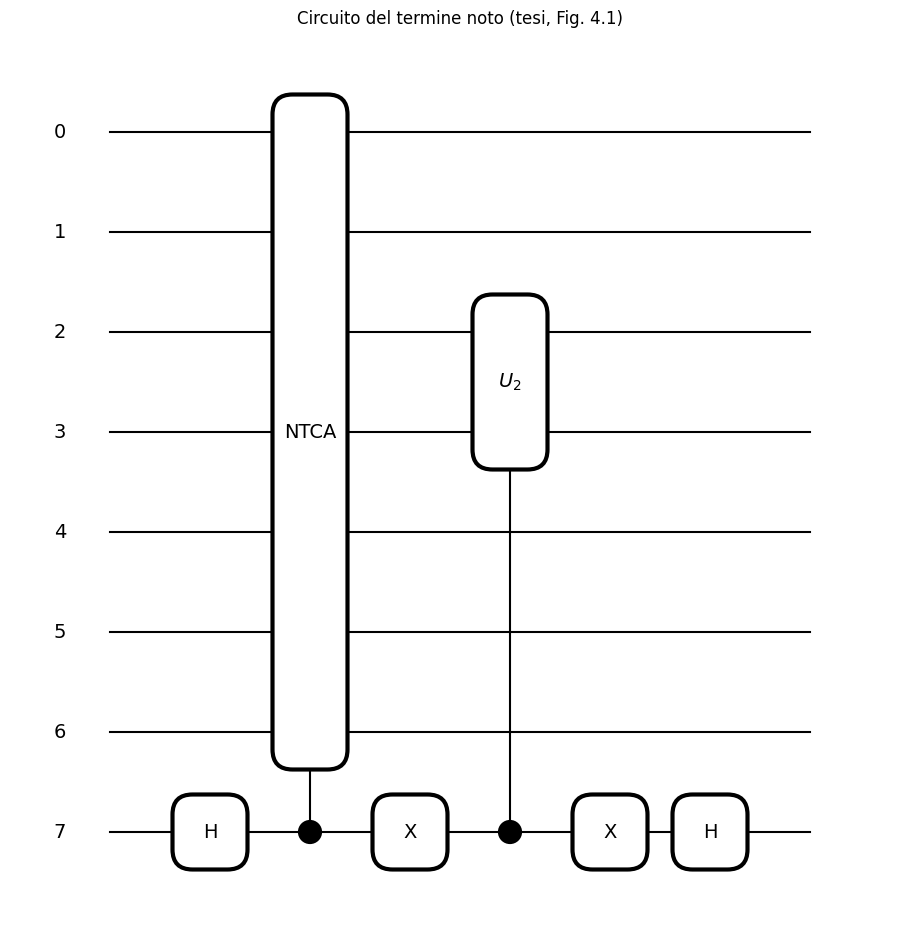

In [25]:
# 5.2 Disegno del circuito del termine noto: NTCA e U_2 come blocchi
if termine_noto_calcolato:
    fig, ax = qml.draw_mpl(circuito_termine_noto, wire_order=fili_termine_noto)()
    ax.set_title("Circuito del termine noto (tesi, Fig. 4.1)")
    plt.show()
else:
    print("Termine noto non calcolato (vedi la cella precedente).")

### 5.3 Verifica classica del termine noto

Confronto con $P(x_k) + 1$ (metodo A) o $f(x_k) + 1$ (metodo B).

In [26]:
if termine_noto_calcolato:
    stampa_valori_attesi(x, funzione_obiettivo, termine_noto=1.0)
else:
    print("Termine noto non calcolato (vedi la cella precedente).")

--- VERIFICA DI COERENZA CLASSICA ---
Indirizzo |0> : 1.6916
Indirizzo |1> : 0.5776
Indirizzo |2> : 0.7548
Indirizzo |3> : 1.0998



### 5.4 Simulazione con misure del termine noto

*Fonti:* [Guo: Sez. IV | Tesi: Sez. 4.5.1, Sez. 4.5.2 | Martyn: — | Gilyén: —]

Con il termine noto l'ampiezza dell'indirizzo $k$ vale $\big(P(x_k) + 1\big)/(2\sqrt{N})$, che è sempre $\ge 0$ perché $|P| \le 1$. Allora dal conteggio si ricava $P$ **con il segno**: $P(x_k) \approx 2\sqrt{N \cdot \text{conteggio}_k / \text{shot}} - 1$. È il motivo per cui Guo stima $(1 + F)/2$ invece di $F$. Il circuito è `circuito_termine_noto`, lo stesso della sezione 5, eseguito con `qml.sample` invece di `qml.state`.

**Errore statistico.** Come nella sezione 4, ma con $q_k = \big(P(x_k)+1\big)^2/(4N)$ e la stima $2\sqrt{N n_k/M} - 1$: $\sigma_k = \sqrt{N(1 - q_k)/M} \approx \sqrt{N/M}$, il doppio che senza termine noto. È il prezzo del segno.

In [27]:
# 5.4 Simulazione con misure del termine noto  [Guo: Sez. IV | Tesi: Sez. 4.5.1, Sez. 4.5.2 | Martyn: — | Gilyén: —]
if termine_noto_calcolato:
    dev_misure_u = qml.device("default.qubit", wires=fili_termine_noto, seed=1234)

    @qml.set_shots(NUMERO_SHOTS)
    @partial(qml.transforms.decompose, gate_set=PORTE_ELEMENTARI)   # esegue le porte elementari (cella dei blocchi)
    @qml.qnode(dev_misure_u)
    def misura_termine_noto():
        circuito_termine_noto()
        return qml.sample(wires=fili_termine_noto)

    campioni_u = misura_termine_noto()
    colonne_a_zero_u = [fili_termine_noto.index(filo) for filo in fili_a_zero + ancilla_ultima]
    colonne_indirizzo_u = [fili_termine_noto.index(filo) for filo in qubits_address]
    tenuti_u = campioni_u[np.all(campioni_u[:, colonne_a_zero_u] == 0, axis=1)]
    conteggi_u = np.bincount(tenuti_u[:, colonne_indirizzo_u] @ pesi_bit, minlength=N_pad)

    # Errore statistico atteso: sigma_k = sqrt(N (1 - q_k) / M), q_k = ((P + 1)/2)^2 / N
    q_u = (valori_termine_noto / 2)**2 / N_pad
    sigma_u = np.sqrt(N_pad * (1 - q_u) / NUMERO_SHOTS)
    P_stimati_u = 2 * np.sqrt(N_pad * conteggi_u / NUMERO_SHOTS) - 1
    scarti_u = np.abs(P_stimati_u - (valori_termine_noto - 1))
    # Probabilità di postselezione con il termine noto: p_tn = sum_k q_k = sum_k (c_k(+1))^2 / (4N)
    p_tn = np.sum(q_u)

    print("--- SIMULAZIONE CON MISURE DEL TERMINE NOTO ---")
    print(f"shot (M): {NUMERO_SHOTS}   tenuti (M_ps): {len(tenuti_u)}   frazione (p^_tn): {len(tenuti_u) / NUMERO_SHOTS:.4f}"
          f"   (p_tn esatta = sum_k (c_k(+1))^2 / (4N): {p_tn:.4f})\n")

    # Intestazione su due righe: testo e simbolo della tesi
    intest_testo   = ["k", "bit", "conteggio", "P dal circuito", "P stimato, con segno", "scarto",    "sigma"]
    intest_simboli = ["",  "",    "n_k",       "c_k(+1) - 1",    "P^(x_k)",              "|P^ - P|",  "σ_k"]
    larghezze      = [2,   4,     10,          15,               21,                     10,          7]
    for riga in (intest_testo, intest_simboli):
        print(" ".join(f"{t:>{w}}" for t, w in zip(riga, larghezze)))
    for k in range(N_pad):
        print(f"{k:>2} {format(k, f'0{n}b'):>4} {conteggi_u[k]:>10} {valori_termine_noto[k] - 1:>+15.4f} {P_stimati_u[k]:>+21.4f}"
              f" {scarti_u[k]:>10.4f} {sigma_u[k]:>7.4f}")
    print(f"\nScarto massimo, max_k |P^(x_k) - (c_k(+1) - 1)|: {scarti_u.max():.4f}   sigma attesa, σ ~ sqrt(N/M) = {np.sqrt(N_pad / NUMERO_SHOTS):.4f}"
          f"   scarto massimo in unità di sigma: {np.max(scarti_u / sigma_u):.1f}")
else:
    print("Termine noto non calcolato (vedi la sezione 5).")

--- SIMULAZIONE CON MISURE DEL TERMINE NOTO ---
shot (M): 10000   tenuti (M_ps): 3114   frazione (p^_tn): 0.3114   (p_tn esatta = sum_k (c_k(+1))^2 / (4N): 0.3108)

 k  bit  conteggio  P dal circuito  P stimato, con segno     scarto   sigma
               n_k     c_k(+1) - 1               P^(x_k)   |P^ - P|     σ_k
 0   00       1790         +0.6913               +0.6923     0.0011  0.0181
 1   01        201         -0.4225               -0.4329     0.0104  0.0198
 2   10        373         -0.2449               -0.2275     0.0175  0.0196
 3   11        750         +0.0996               +0.0954     0.0041  0.0192

Scarto massimo, max_k |P^(x_k) - (c_k(+1) - 1)|: 0.0175   sigma attesa, σ ~ sqrt(N/M) = 0.0200   scarto massimo in unità di sigma: 0.9


## 6. Risultati e conclusioni

### 6.1 Cosa è verificato, metriche, risorse e limiti

**Cosa fa il notebook.** Implementa il caso reale dell'algoritmo NTCA di Guo et al.: a partire dall'oracolo che prepara $\sum_k x_k|k\rangle$ costruisce il block encoding $\tilde G$ delle ampiezze [Guo: Teorema 4 | Tesi: Sez. 4.2 | Martyn: — | Gilyén: —] e gli applica con la QSVT un polinomio $P$ [Guo: Lemma 3 | Tesi: Lemma 3.1, Sez. 3.4.3 | Martyn: Teorema 3 (Sez. II.C) | Gilyén: Teorema 56], ottenendo uno stato con ampiezze proporzionali a $P(x_k)$ [Guo: Teorema 5, Eq. (22) | Tesi: Sez. 4.3.3, Eq. (4.30) | Martyn: — | Gilyén: —]. La sezione 5 aggiunge un termine noto con una LCU.

**Cosa è verificato.**
- Gli autovalori di $G$ e del blocco di $\tilde G$, nella sezione 2 (se $N \le$ `N_MAX_VERIFICHE`).
- I valori del circuito coincidono con il polinomio $P'$ realizzato dagli angoli, fino agli errori numerici. La distanza dalla funzione obiettivo misura solo l'approssimazione polinomiale, negli $x_k$ e su tutto $[-1, 1]$.
- La rotazione di fase della Fig. 1b di Gilyen equivale a `PCPhase`$(\pm\varphi)$ (sezione 3.3) e le ampiezze estratte hanno parte immaginaria nulla (sezioni 4 e 5).
- La probabilità di postselezione simulata coincide con la formula (sezione 4, «Lettura dei risultati»).
- Il termine noto dà $P(x_k) + 1$ quando $s = 1$.
- La simulazione con misure (shot) riproduce $p$ e le frequenze degli indirizzi entro l'errore statistico atteso $\sigma$ (stampato, con lo scarto massimo in unità di $\sigma$): senza termine noto si stima solo $|P(x_k)|$, con il termine noto anche il segno.

**Metriche (capitolo 5 della tesi).** Notazione: $c_k$ = `valori_circuito`, $c_k^{(+1)}$ = `valori_termine_noto`, $P'(x_k)$ = `polinomio_k`, $f(x_k)$ = `obiettivo_k`, $s$ = `scala_qsvt`, $M$ = `NUMERO_SHOTS`, $n_k$ = `conteggi`. Ogni riga di output riporta sia il testo sia il simbolo, per cercarla con Ctrl+F.

| Simbolo | Significato | Variabile | Riga di output | Cella |
|---|---|---|---|---|
| $\varepsilon_{\mathrm{impl}}$ | $\max_k \lvert c_k - P'(x_k)\rvert$: il circuito realizza il polinomio degli angoli | `errore_impl` | «Errore di implementazione, ε_impl» | Riepilogo dei risultati; riepilogo finale |
| $\varepsilon_{\mathrm{dati}}$ | $\max_k \lvert c_k - f(x_k)\rvert$: approssimazione negli $x_k$ | `errore_dati` | «Errore massimo rispetto all'obiettivo, ε_dati» | Riepilogo dei risultati; riepilogo finale |
| $\varepsilon_\infty$ | $\max_{[-1,1]} \lvert P'(x) - f(x)\rvert$: approssimazione su tutto l'intervallo | `errore_intervallo` | «Errore massimo su [-1, 1], ε_∞» | Riepilogo dei risultati; riepilogo finale |
| $\varepsilon_{\mathrm{tn}}$ | $\max_k \lvert c_k^{(+1)} - (f(x_k)+1)\rvert$: termine noto | `errore_tn` | «Termine noto, errore massimo …, ε_tn» | riepilogo finale |
| $p$ | probabilità di postselezione, $\sum_k \lvert b_k\rvert^2 = \sum_k P'(x_k)^2/(s^2N)$ | `p_simulata`, `p_formula` | «p simulata», «p dalla formula» | Lettura dei risultati |
| $1/p$ | esecuzioni medie per un successo | `1 / p_simulata` | «1/p, esecuzioni in media» | Lettura dei risultati |
| $p_{\mathrm{Guo}}$ | $p$ con la scala di Guo $P'/(4\gamma)$ | `p_guo` | «p_Guo, con la scala del paper» | Lettura dei risultati |
| $\hat p$ | frazione di shot tenuti | `len(tenuti) / NUMERO_SHOTS` | «frazione (p^)» | Simulazione con misure (sez. 4) |
| $p_{\mathrm{tn}}$, $\hat p_{\mathrm{tn}}$ | postselezione con termine noto, $\sum_k (c_k^{(+1)})^2/(4N)$, e sua stima | `p_tn` | «p_tn esatta», «frazione (p^_tn)» | Simulazione con misure del termine noto |
| $\lvert\hat P(x_k)\rvert$ | stima del modulo, $s\sqrt{N n_k/M}$ | `P_stimati` | colonna «stimato», simbolo «P^(x_k)» | Simulazione con misure (sez. 4) |
| $\hat P(x_k)$ | stima con segno, $2\sqrt{N n_k/M} - 1$ | `P_stimati_u` | colonna «P stimato, con segno» | Simulazione con misure del termine noto |
| $\sigma_k$, scarto | errore statistico atteso e scarto osservato | `sigma_k`, `scarti`; `sigma_u`, `scarti_u` | colonne «sigma», «scarto»; «Scarto massimo» | Simulazione con misure (sez. 4 e 5) |
| risorse | qubit, porte, profondità del circuito scomposto | `risorse`, `tipi` | «qubit: … porte: … profondità: …» | Lettura dei risultati |

**Risorse.** Il circuito finale usa $2n + 3$ qubit: due ancille (`ancilla_reale`, `ancilla_gtilde`) oltre ai registri ad, da e B, invece delle tre di Guo (sezione 1). $\tilde G$ entra nella QSVT come blocco delle sue porte; i disegni sono a blocchi, su più livelli.

**Per la tesi: costo della parte reale nel circuito.** Rispetto a usare direttamente `qml.PCPhase`, senza ancilla, e prendere la parte reale con `.real`: +1 qubit (`ancilla_reale`), $2(d+1)$ CNOT e $4(d+1)$ porte $X$ (i $C_\Pi\mathrm{NOT}$ controllati su 0), 2 Hadamard. Con $\tanh$ di grado 5 ($d = 5$, 6 angoli): 12 CNOT e 24 $X$. In cambio lo stato preparato contiene $P(x_k)$ e non $P(x_k) + i\,R(x_k)$.

**Limiti.** I risultati sono letti dal vettore di stato del simulatore e non stimati con misure e postselezione (cosa servirebbe su hardware: sezione 4, «Lettura dei risultati»); il circuito, scomposto in porte elementari, è troppo profondo per l'hardware rumoroso di oggi; il termine noto vale solo per $s = 1$ e il polinomio deve avere parità definita.

La cella seguente riassume i numeri dell'esecuzione corrente.

### 6.2 Riepilogo dell'esecuzione corrente

In [28]:
# 6.2 Riepilogo dell'esecuzione corrente
print(f"Esempio: {SCELTA_DATI}  (N = {N_originale}, n = {n})")
print(f"Obiettivo: {nome_obiettivo}  | parità {parita}, grado {len(coefficienti_qsvt) - 1}, scala {scala_qsvt}")
print(f"Qubit del circuito finale: {len(tutti_i_fili)} (2n + 3)")
print()
print(f"Errore di implementazione, ε_impl = max_k |c_k - P'(x_k)|: {errore_impl:.2e}")
print("Circuito = P'(x_k) (tolleranza 1e-8):", np.allclose(valori_circuito, polinomio_k, atol=1e-8))
print(f"Errore massimo rispetto all'obiettivo, ε_dati = max_k |c_k - f(x_k)|: {errore_dati:.2e}")
print(f"Errore massimo su [-1, 1], ε_∞ = max_x |P'(x) - f(x)| (griglia): {errore_intervallo:.2e}")
if termine_noto_calcolato:
    errore_tn = np.max(np.abs(valori_termine_noto - (obiettivo_k + 1)))
    print(f"Termine noto, errore massimo rispetto a obiettivo + 1, ε_tn = max_k |c_k(+1) - (f(x_k) + 1)|: {errore_tn:.2e}")
else:
    print("Termine noto: non calcolato")

Esempio: N4_max085  (N = 4, n = 2)
Obiettivo: f(x) = tanh(x)  | parità dispari, grado 5, scala 1.0
Qubit del circuito finale: 7 (2n + 3)

Errore di implementazione, ε_impl = max_k |c_k - P'(x_k)|: 1.25e-14
Circuito = P'(x_k) (tolleranza 1e-8): True
Errore massimo rispetto all'obiettivo, ε_dati = max_k |c_k - f(x_k)|: 3.65e-04
Errore massimo su [-1, 1], ε_∞ = max_x |P'(x) - f(x)| (griglia): 8.51e-04
Termine noto, errore massimo rispetto a obiettivo + 1, ε_tn = max_k |c_k(+1) - (f(x_k) + 1)|: 3.65e-04


## 7. Cosa è cambiato rispetto alle versioni precedenti

### 7.1 Aggiunte per il capitolo 5 (metriche)

Nessun valore calcolato cambia; si aggiungono stampe.
- Riepilogo dei risultati (sezione 4) e riepilogo finale: errore massimo su tutto $[-1, 1]$ (griglia del grafico) oltre a quello negli $x_k$.
- Simulazione con misure (sezioni 4 e 5): colonne con lo scarto tra stima e valore del circuito e con l'errore statistico atteso $\sigma_k$ (binomiale, propagazione dell'errore); scarto massimo anche in unità di $\sigma$.
- Etichette degli output con testo e simbolo della tesi ($\varepsilon_{\mathrm{impl}}$, $\varepsilon_{\mathrm{dati}}$, $\varepsilon_\infty$, $\varepsilon_{\mathrm{tn}}$, $p$, $p_{\mathrm{Guo}}$, $\hat p$, $\sigma$); intestazioni delle tabelle su due righe (testo e simbolo). Nelle tabelle degli shot la colonna dei valori del circuito si chiama $c_k$ invece di `P(x_k)`.
- Nuove variabili `errore_impl` ed `errore_dati`; nuova riga con il valore di $\varepsilon_{\mathrm{impl}}$ (prima c'era solo il test con tolleranza).
- Probabilità di postselezione: le due scale ($P'/s$ per un polinomio reale di parità definita; $P'/(4\gamma)$ del Lemma 3 di Guo, parità qualsiasi) spiegate nel testo della 4.3, con una tabella dei tre casi.
- Termine noto: probabilità di postselezione $p_{\mathrm{tn}} = \sum_k (c_k^{(+1)})^2/(4N)$, confrontata con la frazione di shot tenuti.
- Sezione 6: tabella delle metriche.
- Nuovo esempio `N4_max085` (0.85, −0.45, −0.25, 0.10), scelto come set di riferimento: un valore in saturazione, uno nella zona intermedia, uno nella zona lineare e uno piccolo, due positivi e due negativi, nessuno quasi nullo; con N = 4 girano anche le verifiche della sezione 2. `SCELTA_DATI` vale `N4_max085`.
- Notebook diviso in sezioni e sottosezioni numerate (0–7), struttura aggiornata nella prima cella: le sezioni 1–6 e le sottosezioni 2.1–2.4 e 3.1–3.3 hanno lo stesso numero di prima; «Blocchi» spostato in 1.2 (prima stava dentro la 2.1, il calcolo non cambia); titoli nuovi 4.1, 5.1, 6.1, 6.2; i commenti di titolo delle celle di codice hanno lo stesso numero.
- Termine noto (5.1): l'output delle ampiezze estratte indica che valgono $(P(x_k) + 1)/2$.

### 7.2 Dalla v9_2 alla v10

Cambia il modo di realizzare il gate $\mathcal{P}$: la parte reale del polinomio è presa nel circuito invece che con `.real`. Angoli e valori estratti sono identici alla v9_2.

**Circuito**
- Nuova ancilla `ancilla_reale` (l'ancilla $b$ di Gilyén et al.), sopra `ancilla_gtilde`: i fili passano da $2n+2$ a $2n+3$ e cambiano numerazione (sezione 1); `ancilla_ultima` diventa $2n+3$.
- Rotazioni di fase: `qml.PCPhase` sostituita dalla porta della Fig. 1b di Gilyén et al. ($C_\Pi\mathrm{NOT}$, $R_z(2\varphi)$, $C_\Pi\mathrm{NOT}$), funzione `rotazione_fase`, scritta come le altre funzioni di porte e trasformata in operatore con `qml.prod`.
- `P_corsivo`: Hadamard su `ancilla_reale` prima e dopo la QSVT.
- Estrazione con `ancilla_reale` a 0 (sezioni 4 e 5). Tolto `.real`: al suo posto un controllo che la parte immaginaria sia nulla.

**Celle nuove**
- Verifica e disegno della rotazione di fase della Fig. 1b (sezione 3.3).
- Stampa di tutti gli autovalori di $\tilde G$ e del suo blocco (sezione 2), con quante volte compare ciascuno.
- Lettura dei risultati (sezione 4): probabilità di postselezione simulata confrontata con la formula e con la scala del paper, numero di porte e profondità del circuito scomposto, testo su cosa servirebbe su un computer quantistico.
- Simulazione con misure (`qml.sample`, 10 000 shot, seed fisso) del circuito finale (sezione 4) e del termine noto (sezione 5): postselezione, frequenze degli indirizzi, stima di $|P|$ e, con il termine noto, di $P$ con il segno.

**Testo**
- Input come vettore: tolta `X_matrice` (il vettore diventava una matrice diagonale e poi di nuovo un vettore, eredità dei primi notebook sul block encoding). `x_classico_grezzo` si legge direttamente da `ESEMPI_DATI`; `ESEMPI_X` e `SCELTA_X` rinominati `ESEMPI_DATI` e `SCELTA_DATI`. Risultati identici.
- Sezione 1: paragrafo su normalizzazione e dati grezzi (il polinomio agisce sui valori normalizzati, che non si riportano indietro moltiplicando per la norma).
- Disegni a blocchi su più livelli: nuova classe `Blocco` (operatore con un nome per il disegno e la scomposizione per il calcolo) usata per $W$, $G$, $\tilde G$ e le rotazioni di fase; $\tilde G$ passato alla QSVT come blocco invece che con `qml.prod`; nuovo disegno di $\mathcal{P}$ con la QSVT aperta di un livello. Risultati identici.
- Blocchi anche per l'oracolo $U$ (in $W$), per $S_0$ (in $G$), per $\mathcal{P}$ (nel circuito finale) e per il circuito NTCA e $U_2$ (nel termine noto); nuovo disegno del circuito del termine noto.
- Esempi con $N = 8$ (`N8_max042`, `N8_max059`). I qnode eseguono il circuito scomposto in porte elementari (`PORTE_ELEMENTARI`): stessi risultati, ma con $N = 16$ circa 30 s invece di oltre 10 minuti. Nuovo parametro `N_MAX_VERIFICHE`: oltre questa dimensione le verifiche con matrici intere vengono saltate.
- Riferimenti alle fonti nel formato a quadrupla [Guo | Tesi | Martyn | Gilyén], spiegato in cima al notebook.
- Sezioni 1, 3.3, 4 e 6 aggiornate; costo della parte reale nel circuito segnato per la tesi (sezioni 3.3 e 6).
- Il notebook si legge senza le versioni precedenti: le altre versioni sono citate solo nella storia del lavoro e in questa cella; `qml.PCPhase` è presentato all'inizio della sezione 3.3; la frase sulla v9_1 nella sezione 5 è riformulata senza riferimento alla versione.

### 7.3 Dalla v9_1 alla v9_2

Il calcolo è lo stesso della v9_1: angoli e risultati sono identici (verificato confrontando gli output con l'esempio predefinito e con altri esempi). Cambiano i fili, il modo di passare $\tilde G$ alla QSVT, i controlli e l'organizzazione.

**Circuito**
- Tolte `ancilla_finale` (nessuna porta) e `ancilla_pcorsivo` (sempre a 0): `PCPhase` agisce solo su `ancilla_gtilde`. I fili passano da $2n+4$ a $2n+2$ e cambiano numerazione (sezione 1).
- $\tilde G$ passato a `qml.QSVT` come `qml.prod(G_tilde)()` invece che come `QubitUnitary` della sua matrice. Tolto il calcolo della matrice dalla cella QSVT (resta la verifica della sezione 2).
- Termine noto: aggiunta la seconda $X$ su `ancilla_ultima` prima dell'ultima Hadamard, come nel circuito di riferimento. I valori estratti non cambiano.

**Controlli**
- Polinomi di parità mista: il notebook si ferma con un errore (tolleranza `TOLLERANZA_PARITA` = $10^{-10}$) invece di azzerare i coefficienti senza avvisare. Nel metodo B si controlla che la parità dichiarata sia quella del fit.
- Termine noto: errore se `scala_qsvt` $\ne 1$; la condizione `if(isPari!=1)` è sostituita da un controllo esplicito sulla parità.

**Organizzazione**
- Tutti i parametri nella cella dei parametri, compresi `usa_metodo_A`, la funzione, la parità e il grado del metodo B.
- Stampa delle versioni di Python e delle librerie.
- Cella degli operatori divisa in quattro ($U$ e $S_0$, $W$, $G$, $\tilde G$) e cella QSVT divisa in tre (polinomio, angoli, gate $\mathcal{P}$), ognuna con il suo testo.
- `circuito_stato_finale` definito una volta sola (senza misura) e riusato nel disegno e nel termine noto; `calcola_stato_finale` restituisce il vettore di stato.
- Funzione unica `estrai_risultati` che legge le ampiezze per nome del filo; sostituisce i due cicli sui bit.
- Verifiche classiche A/B e A1/B1 unificate in `stampa_valori_attesi`; funzione obiettivo definita una volta sola nella sezione 3.1.
- Nuova sezione "Risultati e conclusioni"; questa cella spostata in fondo.

**Pulizia**
- Tolte le funzioni non usate `test_poly_to_angles` e `test_qsvt_build`, gli angoli manuali commentati e i commenti `#poly`, `#lista_coefficienti`, `#test_poly_to_angles`.
- Lasciati i commenti storici: `AmplitudeEmbedding` sopra `MottonenStatePreparation` e il calcolo degli angoli con PyQSP.
- Testo del termine noto: nota sulle due $X$ e sul rimedio per $s \ne 1$.
- Parte immaginaria dell'uscita della QSVT chiamata $R(x)$ invece di $Q(x)$, per non confonderla con la funzione $Q$ del paper (parti immaginarie dei dati, non implementata).
- Sezione 3.1: specificate nel testo le differenze tra il fattore di scala $s$ e il $\gamma$ della tesi (Eq. 4.19).

### 7.4 Dalla v9 alla v9_1

Il calcolo è lo stesso della v9: circuito, angoli e risultati sono identici (verificato confrontando gli output). Le modifiche riguardano ordine, testo e controlli.

**Testo e struttura**
- Aggiunti il titolo con riferimento al paper, l'indice e una cella di testo prima di ogni sezione, con formule e riferimenti a equazioni e figure di Guo et al. e di Gilyén et al.
- La cella di codice `# PROBLEMI` è diventata la sezione di testo "Storia del lavoro".
- Aggiunte note su: corrispondenza tra fili e notazione del paper, `ancilla_finale` e `ancilla_pcorsivo`, uso di `.real`, uso di `QubitUnitary`, fattore di scala nel termine noto.
- Aggiunta la sezione finale "Problemi aperti".

**Parametri**
- Nuova cella dei parametri con i dizionari `ESEMPI_X` (9 matrici) e `ESEMPI_POLINOMI` (18 polinomi) e le scelte `SCELTA_X` e `SCELTA_POLINOMIO`. Gli esempi selezionati sono gli stessi della v9 (SET 2, ora `N4_max055`, e il polinomio `pari_c`).
- Tolti gli esempi commentati dalla cella dei dati (matrici) e dalla cella QSVT (liste di coefficienti).
- Esempi di `ESEMPI_X` riordinati per dimensione N e, a parità di N, dal più uniforme al più sbilanciato dopo la normalizzazione. I commenti ora descrivono i valori normalizzati (tra parentesi), perché il notebook normalizza sempre il vettore: i vecchi commenti dei SET 1–3 ("zona lineare", "saturazione forte") valevano solo per i valori grezzi.
- Chiavi di `ESEMPI_X` rinominate come `N<dimensione>_max<valore massimo dopo la normalizzazione>` (per esempio `set2_estremi` → `N4_max055`); il vecchio nome è indicato nel commento. `SCELTA_X` vale `N4_max055`, lo stesso esempio di prima.

**Cella dei dati e dei fili**
- Tolte le variabili create e mai usate: `qubits_ad_da_B`, `qubits_pcorsivo_gtilde_ad_da_b`, `ancille_qsvt`.
- Aggiornati i commenti: ruolo delle ancille, esempi di fili per n = 2, numero totale di fili (2n+4).

**Cella QSVT**
- Tolto il fallback con angoli fittizi: se il calcolo degli angoli fallisce, il notebook si ferma con un errore.
- Tolto il secondo `stato_zero`, creato e mai usato.
- La stampa "Matrice G_tilde 'ritagliata'" ora si chiama "Autovalori del blocco in alto a sinistra di G_tilde".
- Aggiornati i commenti: `QubitUnitary`, proiettore, parametri di `qml.QSVT`, esempio di funzione, calcolo degli angoli (non più PyQSP).
- Restano invariate le funzioni di test `test_poly_to_angles` e `test_qsvt_build`.

**Circuito finale e verifiche**
- Circuito finale: aggiornati i commenti (dimensione del vettore di stato, condizione di estrazione, parte reale).
- Verifiche classiche: le funzioni B e B1 usano il parametro `funzione` invece della variabile globale `mia_funzione`; tolti i parametri mai usati `polinomio_pari` e `funzione_pari`.
- Cella del termine noto: corretto solo il commento sulla dimensione del vettore di stato (512 elementi con n = 2).

**Celle nuove**
- Verifica degli autovalori di $G$ (Eq. 12).
- Verifica del blocco di $\tilde G$ (Eq. 13) e dei suoi autovalori (Eq. 6).
- Disegni di $W$, $G$, $\tilde G$ e del circuito finale.
- Riepilogo con grafico (obiettivo, polinomio realizzato dagli angoli, valori del circuito) e tabella degli errori.